# Xây Dựng Các Mô Hình Phức Tập: Anomaly Detection & Deep Learning

Notebook này triển khai toàn diện thực nghiệm **Phát hiện Gian lận Bất thường (Anomaly Detection)** và **Học Sâu trên Dữ liệu Bảng (Tabular Deep Learning)** cho bài toán **Credit Card Fraud Prediction** theo bản kế hoạch chi tiết tại `plan.md`, tích hợp trực tiếp với khung kiểm thử chuẩn Stratified 5-Fold CV (`validation_pipeline.py`).

### Phạm vi thực nghiệm
1. **Đóng gói Shared Module (`anomaly_dl_pipeline.py`) & Chống Rò Rỉ Dữ Liệu (Zero Data Leakage):**
   - Xuất trực tiếp module dùng chung qua `%%writefile anomaly_dl_pipeline.py` (tuân thủ `requirement.md`).
   - Toàn bộ phép biến đổi phân phối (`np.log1p` cho biến lệch phải), chuẩn hóa (`StandardScaler`), mã hóa (`OneHotEncoder`), huấn luyện mô hình One-Class (`y_train == 0`) và chuẩn hóa điểm bất thường về xác suất $[0, 1]$ chỉ được `.fit()` trên `X_train` bên trong từng fold.
2. **Giai đoạn 1 — Isolation Forest (`EXP-IF.1` $\rightarrow$ `EXP-IF.4`):**
   - Khảo sát Isolation Forest không giám sát (`max_samples=256` vs `4096`), bán giám sát (`fit_mode="normal_only"` chỉ dựng cây cô lập trên giao dịch hợp lệ để tránh hiện tượng *masking*), và lấy mẫu không gian con đặc trưng (`max_features=0.7`).
3. **Giai đoạn 2 — Deep Autoencoder Anomaly Detection (`EXP-AE.1` $\rightarrow$ `EXP-AE.4`):**
   - Huấn luyện mạng Autoencoder đa tầng chỉ trên giao dịch hợp lệ (`y_train == 0`) để phát hiện gian lận qua đột biến Sai số Tái tạo (Reconstruction Error): so sánh `Standard AE (latent=16)`, `Tight-Bottleneck AE (latent=8)`, `Denoising Autoencoder (DAE)`, và `Multi-Metric Anomaly Score (MSE + CoreMSE + MaxSpike + Cosine)`.
4. **Giai đoạn 3 — Supervised & Semi-Supervised Deep Learning (`EXP-DL.1` $\rightarrow$ `EXP-DL.4`):**
   - Khảo sát mạng `Tabular MLP`, `Tabular ResNet-MLP` (với `pos_weight=sqrt(IR)` và `Focal Loss`), và kiến trúc lai **`Joint Supervised Autoencoder (SupAE)`** kết hợp đồng thời nhánh Decoder tái tạo bất thường và nhánh Classifier Head phân lớp gian lận.
5. **Giai đoạn 4 — Hybrid Anomaly-Enriched GBDT & Cross-Paradigm Ensemble (`EXP-HYB.1` $\rightarrow$ `EXP-HYB.5`):**
   - Trích xuất điểm cô lập từ **Isolation Forest** + sai số tái tạo & biểu diễn nút cổ chai (`Latent Bottleneck`) từ **Autoencoder** làm đặc trưng đầu vào bổ sung (Meta-Features) cho **LightGBM** và **CatBoost (`SqrtBalanced`)**.
   - Kết hợp đa trường phái (**Cross-Paradigm Ensemble: Anomaly-Enriched GBDT + Deep Learning**) để thiết lập kỷ lục mới về `OOF_AUPRC` và `Best_F1`.


In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
)
from sklearn.decomposition import PCA
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from validation_pipeline import run_cv_pipeline, evaluate_fraud_predictions

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Đảm bảo train_folds.csv tồn tại với đúng StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
if not os.path.exists("train_folds.csv"):
    print("train_folds.csv chưa tồn tại -> Đang khởi tạo từ train.csv...")
    df_raw = pd.read_csv("train.csv")
    df_raw["fold"] = -1
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for fold, (_, val_idx) in enumerate(skf.split(df_raw, df_raw["is_fraud"])):
        df_raw.loc[val_idx, "fold"] = fold
    df_raw["fold"] = df_raw["fold"].astype(int)
    df_raw.to_csv("train_folds.csv", index=False)

df_folds = pd.read_csv("train_folds.csv")
y_full = df_folds["is_fraud"].values.astype(int)
folds_full = df_folds["fold"].values

n_neg = int(np.sum(y_full == 0))
n_pos = int(np.sum(y_full == 1))
IR = n_neg / n_pos
SQRT_IR = float(np.sqrt(IR))
CONTAMINATION = float(n_pos / len(y_full))

print(f"PyTorch version: {torch.__version__} | CPU Threads: {torch.get_num_threads()}")
print(f"Dataset shape  : {df_folds.shape}")
print(f"Normal (0)     : {n_neg:,} ({n_neg/len(y_full)*100:.3f}%)")
print(f"Fraud  (1)     : {n_pos:,} ({n_pos/len(y_full)*100:.3f}%) | Contamination = {CONTAMINATION:.5f}")
print(f"Imbalance Ratio: IR = {IR:.3f} | sqrt(IR) = {SQRT_IR:.3f}")


PyTorch version: 2.15.0+cpu | CPU Threads: 8
Dataset shape  : (699960, 27)
Normal (0)     : 688,271 (98.330%)
Fraud  (1)     : 11,689 (1.670%) | Contamination = 0.01670
Imbalance Ratio: IR = 58.882 | sqrt(IR) = 7.673


---
## 1. Đóng Gói Module Dùng Chung `anomaly_dl_pipeline.py` & Kiểm Chứng Pipeline

Tuân thủ `requirement.md`, toàn bộ kiến trúc `IsolationForestFraudDetector`, `TabularAutoencoderNet`, `AutoencoderFraudDetector`, `TabularMLPNet`, `JointSupAENet`, `DeepTabularFraudClassifier`, cùng các hàm tiền xử lý chống rò rỉ dữ liệu (`make_dl_preprocess_fn`, `make_anomaly_enriched_preprocess_fn`) được đóng gói và xuất trực tiếp ra file `anomaly_dl_pipeline.py` bằng `%%writefile`.


In [2]:
%%writefile anomaly_dl_pipeline.py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

NUM_COLS = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]

SKEWED_NUM_COLS = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "account_balance_usd",
]

BINARY_FLAGS = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]

CAT_COLS = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
]

ALL_FEATURES = NUM_COLS + BINARY_FLAGS + CAT_COLS


def set_all_seeds(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _calibrate_scores_to_prob(train_scores, eval_scores):
    """
    Fit calibration parameters (mean, std) strictly on train_scores
    and map eval_scores to (0, 1) via logistic sigmoid over z-scores.
    """
    mu = float(np.mean(train_scores))
    sigma = float(np.std(train_scores)) + 1e-8
    z = np.clip((eval_scores - mu) / sigma, -25.0, 25.0)
    probs = 1.0 / (1.0 + np.exp(-z))
    return probs.astype(np.float64), mu, sigma


def make_dl_preprocess_fn(
    log_transform_skewed=True,
    scale_numeric=True,
    encode_mode="onehot",
):
    """
    Return preprocess_fn(X_train, y_train, X_val) compatible with
    validation_pipeline.run_cv_pipeline().

    Strict Zero Data Leakage:
    - Log1p is applied to right-skewed positive numeric columns.
    - StandardScaler and OneHotEncoder/OrdinalEncoder are fit strictly on X_train.
    - X_val is transformed only.
    """
    def preprocess_fn(X_train, y_train, X_val):
        num_cols = [c for c in NUM_COLS if c in X_train.columns]
        bin_cols = [c for c in BINARY_FLAGS if c in X_train.columns]
        cat_cols = [c for c in CAT_COLS if c in X_train.columns]

        tr_parts = []
        va_parts = []
        out_cols = []

        # 1. Numeric features
        if num_cols:
            X_tr_num = X_train[num_cols].to_numpy(dtype=np.float32, copy=True)
            X_va_num = X_val[num_cols].to_numpy(dtype=np.float32, copy=True)
            if log_transform_skewed:
                for idx, col_name in enumerate(num_cols):
                    if col_name in SKEWED_NUM_COLS:
                        X_tr_num[:, idx] = np.log1p(np.maximum(X_tr_num[:, idx], 0.0))
                        X_va_num[:, idx] = np.log1p(np.maximum(X_va_num[:, idx], 0.0))
            if scale_numeric:
                scaler = StandardScaler()
                X_tr_num = scaler.fit_transform(X_tr_num).astype(np.float32)
                X_va_num = scaler.transform(X_va_num).astype(np.float32)
            tr_parts.append(X_tr_num)
            va_parts.append(X_va_num)
            out_cols.extend(num_cols)

        # 2. Binary flags
        if bin_cols:
            X_tr_bin = X_train[bin_cols].astype(np.float32).to_numpy()
            X_va_bin = X_val[bin_cols].astype(np.float32).to_numpy()
            tr_parts.append(X_tr_bin)
            va_parts.append(X_va_bin)
            out_cols.extend(bin_cols)

        # 3. Categorical features
        if cat_cols:
            if encode_mode == "onehot":
                enc = OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32,
                )
                X_tr_cat = enc.fit_transform(X_train[cat_cols])
                X_va_cat = enc.transform(X_val[cat_cols])
                cat_names = [
                    name.replace(" ", "_").replace("-", "_")
                    for name in enc.get_feature_names_out(cat_cols)
                ]
            elif encode_mode == "ordinal":
                enc = OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                    dtype=np.float32,
                )
                X_tr_cat = enc.fit_transform(X_train[cat_cols])
                X_va_cat = enc.transform(X_val[cat_cols])
                cat_names = list(cat_cols)
            else:
                raise ValueError(f"Unknown encode_mode: {encode_mode}")

            tr_parts.append(X_tr_cat)
            va_parts.append(X_va_cat)
            out_cols.extend(cat_names)

        X_tr_arr = np.hstack(tr_parts).astype(np.float32)
        X_va_arr = np.hstack(va_parts).astype(np.float32)
        y_tr_arr = np.asarray(y_train, dtype=np.int32)

        X_tr_df = pd.DataFrame(X_tr_arr, columns=out_cols)
        X_va_df = pd.DataFrame(X_va_arr, columns=out_cols, index=X_val.index)
        return X_tr_df, y_tr_arr, X_va_df

    return preprocess_fn


class IsolationForestFraudDetector(BaseEstimator, ClassifierMixin):
    """
    Scikit-learn compatible wrapper around IsolationForest for Fraud Anomaly Detection.
    Supports:
    - fit_mode='unsupervised': fit on all X_train samples
    - fit_mode='normal_only': fit strictly on normal transactions X_train[y_train == 0]
    """

    def __init__(
        self,
        n_estimators=200,
        max_samples=256,
        contamination=0.0167,
        max_features=1.0,
        fit_mode="unsupervised",
        random_state=42,
        n_jobs=-1,
    ):
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.contamination = contamination
        self.max_features = max_features
        self.fit_mode = fit_mode
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y=None):
        X_arr = np.array(X, dtype=np.float32, copy=True)
        if self.fit_mode == "normal_only" and y is not None:
            y_arr = np.asarray(y)
            X_fit = X_arr[y_arr == 0]
        else:
            X_fit = X_arr

        self.iforest_ = IsolationForest(
            n_estimators=self.n_estimators,
            max_samples=self.max_samples,
            contamination=self.contamination,
            max_features=self.max_features,
            random_state=self.random_state,
            n_jobs=self.n_jobs,
        )
        self.iforest_.fit(X_fit)

        # Calibrate raw anomaly score distribution strictly on X_train
        raw_train_scores = -self.iforest_.score_samples(X_arr)
        self.score_mean_ = float(np.mean(raw_train_scores))
        self.score_std_ = float(np.std(raw_train_scores)) + 1e-8
        self.classes_ = np.array([0, 1])
        return self

    def raw_anomaly_score(self, X):
        X_arr = np.array(X, dtype=np.float32, copy=True)
        return -self.iforest_.score_samples(X_arr)

    def predict_proba(self, X):
        raw_scores = self.raw_anomaly_score(X)
        z = np.clip((raw_scores - self.score_mean_) / self.score_std_, -25.0, 25.0)
        p1 = 1.0 / (1.0 + np.exp(-z))
        p0 = 1.0 - p1
        return np.column_stack([p0, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class TabularAutoencoderNet(nn.Module):
    """
    Deep Undercomplete / Denoising Autoencoder for Tabular Fraud Anomaly Detection.
    """

    def __init__(self, input_dim, hidden_dims=(64, 32), latent_dim=16, dropout=0.1):
        super().__init__()
        h1, h2 = hidden_dims
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.BatchNorm1d(h1),
            nn.SiLU(),
            nn.Dropout(dropout) if dropout > 0 else nn.Identity(),
            nn.Linear(h1, h2),
            nn.BatchNorm1d(h2),
            nn.SiLU(),
            nn.Linear(h2, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2),
            nn.BatchNorm1d(h2),
            nn.SiLU(),
            nn.Linear(h2, h1),
            nn.BatchNorm1d(h1),
            nn.SiLU(),
            nn.Linear(h1, input_dim),
        )

    def forward(self, x, noise_std=0.0):
        if self.training and noise_std > 0.0:
            x_in = x + torch.randn_like(x) * noise_std
        else:
            x_in = x
        z = self.encoder(x_in)
        x_hat = self.decoder(z)
        return x_hat, z


class AutoencoderFraudDetector(BaseEstimator, ClassifierMixin):
    """
    Semi-Supervised One-Class Deep Autoencoder trained strictly on Normal transactions (y == 0).
    Supports:
    - Standard Undercomplete Autoencoder (noise_std=0.0)
    - Denoising Autoencoder (noise_std > 0.0)
    - Multiple anomaly scoring modes: 'mse', 'mae', 'multi' (MSE + MaxSpike + Cosine + NumFlagWeighted)
    """

    def __init__(
        self,
        hidden_dims=(64, 32),
        latent_dim=16,
        dropout=0.05,
        noise_std=0.0,
        score_mode="mse",
        epochs=12,
        batch_size=2048,
        lr=3e-3,
        weight_decay=1e-4,
        fit_normal_only=True,
        random_state=42,
    ):
        self.hidden_dims = hidden_dims
        self.latent_dim = latent_dim
        self.dropout = dropout
        self.noise_std = noise_std
        self.score_mode = score_mode
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.weight_decay = weight_decay
        self.fit_normal_only = fit_normal_only
        self.random_state = random_state

    def _compute_reconstruction_details(self, X_arr):
        self.model_.eval()
        n = len(X_arr)
        mse_all = np.empty(n, dtype=np.float32)
        mae_all = np.empty(n, dtype=np.float32)
        max_err = np.empty(n, dtype=np.float32)
        cos_dist = np.empty(n, dtype=np.float32)
        num_flag_mse = np.empty(n, dtype=np.float32)
        latents = np.empty((n, self.latent_dim), dtype=np.float32)

        core_dim = min(19, X_arr.shape[1])  # 13 NUM_COLS + 6 BINARY_FLAGS
        eval_bs = 8192

        with torch.no_grad():
            for start in range(0, n, eval_bs):
                end = min(start + eval_bs, n)
                xb = torch.from_numpy(X_arr[start:end])
                x_hat, zb = self.model_(xb, noise_std=0.0)
                diff = xb - x_hat
                sq_err = diff * diff

                mse_all[start:end] = torch.mean(sq_err, dim=1).numpy()
                mae_all[start:end] = torch.mean(torch.abs(diff), dim=1).numpy()
                max_err[start:end] = torch.max(sq_err, dim=1).values.numpy()
                num_flag_mse[start:end] = torch.mean(sq_err[:, :core_dim], dim=1).numpy()
                cos_sim = F.cosine_similarity(xb, x_hat, dim=1, eps=1e-8)
                cos_dist[start:end] = (1.0 - cos_sim).numpy()
                latents[start:end] = zb.numpy()

        return {
            "mse": mse_all,
            "mae": mae_all,
            "max": max_err,
            "cos": cos_dist,
            "num_flag_mse": num_flag_mse,
            "latents": latents,
        }

    def _aggregate_score(self, details, fit_stats=False):
        if self.score_mode == "mse":
            return np.log1p(details["mse"])
        if self.score_mode == "mae":
            return details["mae"]
        if self.score_mode == "multi":
            s_mse = np.log1p(details["mse"])
            s_core = np.log1p(details["num_flag_mse"])
            s_max = np.log1p(details["max"])
            s_cos = details["cos"]
            if fit_stats:
                self.multi_stats_ = {
                    "mse": (float(np.mean(s_mse)), float(np.std(s_mse)) + 1e-8),
                    "core": (float(np.mean(s_core)), float(np.std(s_core)) + 1e-8),
                    "max": (float(np.mean(s_max)), float(np.std(s_max)) + 1e-8),
                    "cos": (float(np.mean(s_cos)), float(np.std(s_cos)) + 1e-8),
                }
            z_mse = (s_mse - self.multi_stats_["mse"][0]) / self.multi_stats_["mse"][1]
            z_core = (s_core - self.multi_stats_["core"][0]) / self.multi_stats_["core"][1]
            z_max = (s_max - self.multi_stats_["max"][0]) / self.multi_stats_["max"][1]
            z_cos = (s_cos - self.multi_stats_["cos"][0]) / self.multi_stats_["cos"][1]
            return 0.35 * z_mse + 0.35 * z_core + 0.15 * z_max + 0.15 * z_cos
        raise ValueError(f"Unknown score_mode: {self.score_mode}")

    def fit(self, X, y=None):
        set_all_seeds(self.random_state)
        X_arr = np.array(X, dtype=np.float32, copy=True)
        if self.fit_normal_only and y is not None:
            y_arr = np.asarray(y)
            X_fit = X_arr[y_arr == 0]
        else:
            X_fit = X_arr

        input_dim = X_arr.shape[1]
        self.model_ = TabularAutoencoderNet(
            input_dim=input_dim,
            hidden_dims=self.hidden_dims,
            latent_dim=self.latent_dim,
            dropout=self.dropout,
        )

        optimizer = torch.optim.AdamW(
            self.model_.parameters(),
            lr=self.lr,
            weight_decay=self.weight_decay,
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=self.epochs, eta_min=self.lr * 0.05
        )

        n_fit = len(X_fit)
        rng = np.random.default_rng(self.random_state)

        self.model_.train()
        for _ in range(self.epochs):
            perm = rng.permutation(n_fit)
            for start in range(0, n_fit, self.batch_size):
                idx = perm[start : start + self.batch_size]
                xb = torch.from_numpy(X_fit[idx])
                optimizer.zero_grad(set_to_none=True)
                x_hat, _ = self.model_(xb, noise_std=self.noise_std)
                loss = F.mse_loss(x_hat, xb)
                loss.backward()
                optimizer.step()
            scheduler.step()

        train_details = self._compute_reconstruction_details(X_arr)
        raw_train_scores = self._aggregate_score(train_details, fit_stats=True)
        self.score_mean_ = float(np.mean(raw_train_scores))
        self.score_std_ = float(np.std(raw_train_scores)) + 1e-8
        self.classes_ = np.array([0, 1])
        return self

    def transform_anomaly_features(self, X):
        X_arr = np.array(X, dtype=np.float32, copy=True)
        return self._compute_reconstruction_details(X_arr)

    def predict_proba(self, X):
        X_arr = np.array(X, dtype=np.float32, copy=True)
        details = self._compute_reconstruction_details(X_arr)
        raw_scores = self._aggregate_score(details, fit_stats=False)
        z = np.clip((raw_scores - self.score_mean_) / self.score_std_, -25.0, 25.0)
        p1 = 1.0 / (1.0 + np.exp(-z))
        p0 = 1.0 - p1
        return np.column_stack([p0, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class ResidualTabularBlock(nn.Module):
    def __init__(self, dim, dropout=0.15):
        super().__init__()
        self.block = nn.Sequential(
            nn.BatchNorm1d(dim),
            nn.SiLU(),
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
        )

    def forward(self, x):
        return x + self.block(x)


class TabularMLPNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(128, 64, 32), dropout=0.15, use_residual=False):
        super().__init__()
        self.use_residual = use_residual
        h1, h2, h3 = hidden_dims
        if not use_residual:
            self.net = nn.Sequential(
                nn.Linear(input_dim, h1),
                nn.BatchNorm1d(h1),
                nn.SiLU(),
                nn.Dropout(dropout),
                nn.Linear(h1, h2),
                nn.BatchNorm1d(h2),
                nn.SiLU(),
                nn.Dropout(dropout),
                nn.Linear(h2, h3),
                nn.BatchNorm1d(h3),
                nn.SiLU(),
                nn.Linear(h3, 1),
            )
        else:
            self.in_proj = nn.Sequential(
                nn.Linear(input_dim, h1),
                nn.BatchNorm1d(h1),
                nn.SiLU(),
            )
            self.res1 = ResidualTabularBlock(h1, dropout=dropout)
            self.down = nn.Sequential(
                nn.Linear(h1, h2),
                nn.BatchNorm1d(h2),
                nn.SiLU(),
            )
            self.res2 = ResidualTabularBlock(h2, dropout=dropout)
            self.head = nn.Sequential(
                nn.BatchNorm1d(h2),
                nn.SiLU(),
                nn.Linear(h2, 1),
            )

    def forward(self, x):
        if not self.use_residual:
            return self.net(x).squeeze(-1)
        h = self.in_proj(x)
        h = self.res1(h)
        h = self.down(h)
        h = self.res2(h)
        return self.head(h).squeeze(-1)


class JointSupAENet(nn.Module):
    """
    Dual-Head Joint Supervised Autoencoder (SupAE):
    - Shared Encoder compresses x -> z
    - Decoder reconstructs x_hat from z
    - Classifier Head takes [x, z, (x - x_hat)^2, ||x - x_hat||_2] to predict fraud logit
    """

    def __init__(self, input_dim, hidden_dim=96, latent_dim=24, dropout=0.15):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.SiLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, input_dim),
        )
        cls_in_dim = input_dim + latent_dim + input_dim + 2
        self.classifier = nn.Sequential(
            nn.Linear(cls_in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.SiLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        sq_diff = (x - x_hat) ** 2
        mse_feat = torch.mean(sq_diff, dim=1, keepdim=True)
        max_feat = torch.max(sq_diff, dim=1, keepdim=True).values
        cls_input = torch.cat([x, z, sq_diff, mse_feat, max_feat], dim=1)
        logits = self.classifier(cls_input).squeeze(-1)
        return logits, x_hat


class DeepTabularFraudClassifier(BaseEstimator, ClassifierMixin):
    """
    Scikit-learn compatible Supervised & Semi-Supervised Deep Tabular Classifier.
    arch in:
    - 'mlp': Standard 3-layer Tabular MLP
    - 'resnet': Residual Tabular Neural Network
    - 'sup_ae': Joint Supervised Autoencoder (Reconstruction + Fraud Classification)
    loss_type in:
    - 'wbce': Weighted Binary Cross-Entropy (pos_weight)
    - 'focal': Binary Focal Loss (gamma=2.0)
    """

    def __init__(
        self,
        arch="mlp",
        loss_type="wbce",
        pos_weight=1.0,
        focal_gamma=2.0,
        recon_weight=0.35,
        hidden_dims=(128, 64, 32),
        latent_dim=24,
        dropout=0.15,
        epochs=12,
        batch_size=2048,
        lr=3e-3,
        weight_decay=1e-4,
        random_state=42,
    ):
        self.arch = arch
        self.loss_type = loss_type
        self.pos_weight = pos_weight
        self.focal_gamma = focal_gamma
        self.recon_weight = recon_weight
        self.hidden_dims = hidden_dims
        self.latent_dim = latent_dim
        self.dropout = dropout
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.weight_decay = weight_decay
        self.random_state = random_state

    def _compute_cls_loss(self, logits, targets):
        if self.loss_type == "wbce":
            pw = torch.tensor(self.pos_weight, dtype=torch.float32)
            return F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pw)
        if self.loss_type == "focal":
            bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
            probs = torch.sigmoid(logits)
            p_t = probs * targets + (1.0 - probs) * (1.0 - targets)
            modulating = (1.0 - p_t) ** self.focal_gamma
            if self.pos_weight != 1.0:
                alpha_w = targets * self.pos_weight + (1.0 - targets)
                return torch.mean(alpha_w * modulating * bce)
            return torch.mean(modulating * bce)
        raise ValueError(f"Unknown loss_type: {self.loss_type}")

    def fit(self, X, y):
        set_all_seeds(self.random_state)
        X_arr = np.array(X, dtype=np.float32, copy=True)
        y_arr = np.array(y, dtype=np.float32, copy=True)
        input_dim = X_arr.shape[1]

        if self.arch == "mlp":
            self.model_ = TabularMLPNet(
                input_dim=input_dim,
                hidden_dims=self.hidden_dims,
                dropout=self.dropout,
                use_residual=False,
            )
        elif self.arch == "resnet":
            self.model_ = TabularMLPNet(
                input_dim=input_dim,
                hidden_dims=self.hidden_dims,
                dropout=self.dropout,
                use_residual=True,
            )
        elif self.arch == "sup_ae":
            self.model_ = JointSupAENet(
                input_dim=input_dim,
                hidden_dim=self.hidden_dims[0],
                latent_dim=self.latent_dim,
                dropout=self.dropout,
            )
        else:
            raise ValueError(f"Unknown arch: {self.arch}")

        optimizer = torch.optim.AdamW(
            self.model_.parameters(),
            lr=self.lr,
            weight_decay=self.weight_decay,
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=self.epochs, eta_min=self.lr * 0.05
        )

        n_samples = len(X_arr)
        rng = np.random.default_rng(self.random_state)

        self.model_.train()
        for _ in range(self.epochs):
            perm = rng.permutation(n_samples)
            for start in range(0, n_samples, self.batch_size):
                idx = perm[start : start + self.batch_size]
                xb = torch.from_numpy(X_arr[idx])
                yb = torch.from_numpy(y_arr[idx])

                optimizer.zero_grad(set_to_none=True)
                if self.arch == "sup_ae":
                    logits, x_hat = self.model_(xb)
                    cls_loss = self._compute_cls_loss(logits, yb)
                    normal_mask = (yb == 0.0).float().unsqueeze(1)
                    rec_loss = torch.mean(normal_mask * ((xb - x_hat) ** 2))
                    loss = cls_loss + self.recon_weight * rec_loss
                else:
                    logits = self.model_(xb)
                    loss = self._compute_cls_loss(logits, yb)

                loss.backward()
                optimizer.step()
            scheduler.step()

        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        X_arr = np.array(X, dtype=np.float32, copy=True)
        self.model_.eval()
        n = len(X_arr)
        p1 = np.empty(n, dtype=np.float64)
        eval_bs = 8192

        with torch.no_grad():
            for start in range(0, n, eval_bs):
                end = min(start + eval_bs, n)
                xb = torch.from_numpy(X_arr[start:end])
                if self.arch == "sup_ae":
                    logits, _ = self.model_(xb)
                else:
                    logits = self.model_(xb)
                p1[start:end] = torch.sigmoid(logits).numpy()

        p0 = 1.0 - p1
        return np.column_stack([p0, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def make_anomaly_enriched_preprocess_fn(
    use_iforest=True,
    use_autoencoder=True,
    ae_latent_dim=8,
    ae_epochs=8,
    if_estimators=150,
    if_max_samples=2048,
    random_state=42,
):
    """
    Higher-order preprocess_fn for validation_pipeline.run_cv_pipeline().
    Inside each CV fold (strictly fit on X_train, y_train):
    1. Standardizes and One-Hot encodes base features.
    2. Fits IsolationForest (unsupervised & normal-only) to extract global isolation scores.
    3. Fits Denoising Autoencoder on X_train[y_train == 0] to extract reconstruction errors
       (MSE, MAE, MaxSpike, Core Num+Flag MSE, Cosine Distance) and Latent Bottleneck features.
    4. Appends all extracted anomaly meta-features to X_train and X_val for GBDT models.
    """
    base_prep = make_dl_preprocess_fn(
        log_transform_skewed=True,
        scale_numeric=True,
        encode_mode="onehot",
    )

    def preprocess_fn(X_train, y_train, X_val):
        X_tr_df, y_tr_arr, X_va_df = base_prep(X_train, y_train, X_val)
        X_tr_arr = X_tr_df.to_numpy(dtype=np.float32)
        X_va_arr = X_va_df.to_numpy(dtype=np.float32)

        extra_tr = []
        extra_va = []
        extra_cols = []

        if use_iforest:
            # 1. Normal-only Isolation Forest score
            if_norm = IsolationForestFraudDetector(
                n_estimators=if_estimators,
                max_samples=if_max_samples,
                fit_mode="normal_only",
                random_state=random_state,
                n_jobs=-1,
            )
            if_norm.fit(X_tr_arr, y_tr_arr)
            tr_if_norm = if_norm.raw_anomaly_score(X_tr_arr).astype(np.float32)
            va_if_norm = if_norm.raw_anomaly_score(X_va_arr).astype(np.float32)

            # 2. Unsupervised Isolation Forest score
            if_unsup = IsolationForestFraudDetector(
                n_estimators=if_estimators,
                max_samples=256,
                fit_mode="unsupervised",
                random_state=random_state + 7,
                n_jobs=-1,
            )
            if_unsup.fit(X_tr_arr)
            tr_if_unsup = if_unsup.raw_anomaly_score(X_tr_arr).astype(np.float32)
            va_if_unsup = if_unsup.raw_anomaly_score(X_va_arr).astype(np.float32)

            extra_tr.extend([tr_if_norm[:, None], tr_if_unsup[:, None]])
            extra_va.extend([va_if_norm[:, None], va_if_unsup[:, None]])
            extra_cols.extend(["iforest_score_normal", "iforest_score_unsup"])

        if use_autoencoder:
            ae = AutoencoderFraudDetector(
                hidden_dims=(64, 32),
                latent_dim=ae_latent_dim,
                dropout=0.05,
                noise_std=0.10,
                score_mode="multi",
                epochs=ae_epochs,
                batch_size=2048,
                lr=3e-3,
                fit_normal_only=True,
                random_state=random_state,
            )
            ae.fit(X_tr_arr, y_tr_arr)
            tr_det = ae.transform_anomaly_features(X_tr_arr)
            va_det = ae.transform_anomaly_features(X_va_arr)

            tr_multi = ae.predict_proba(X_tr_arr)[:, 1].astype(np.float32)
            va_multi = ae.predict_proba(X_va_arr)[:, 1].astype(np.float32)

            extra_tr.extend([
                tr_det["mse"][:, None],
                tr_det["mae"][:, None],
                tr_det["max"][:, None],
                tr_det["num_flag_mse"][:, None],
                tr_det["cos"][:, None],
                tr_multi[:, None],
                tr_det["latents"],
            ])
            extra_va.extend([
                va_det["mse"][:, None],
                va_det["mae"][:, None],
                va_det["max"][:, None],
                va_det["num_flag_mse"][:, None],
                va_det["cos"][:, None],
                va_multi[:, None],
                va_det["latents"],
            ])
            extra_cols.extend([
                "ae_recon_mse",
                "ae_recon_mae",
                "ae_recon_max",
                "ae_recon_core_mse",
                "ae_cos_dist",
                "ae_multi_prob",
            ] + [f"ae_latent_{i}" for i in range(ae_latent_dim)])

        if extra_tr:
            X_tr_full = np.hstack([X_tr_arr] + extra_tr).astype(np.float32)
            X_va_full = np.hstack([X_va_arr] + extra_va).astype(np.float32)
            all_cols = list(X_tr_df.columns) + extra_cols
            X_tr_out = pd.DataFrame(X_tr_full, columns=all_cols)
            X_va_out = pd.DataFrame(X_va_full, columns=all_cols, index=X_val.index)
            return X_tr_out, y_tr_arr, X_va_out

        return X_tr_df, y_tr_arr, X_va_df

    return preprocess_fn


Overwriting anomaly_dl_pipeline.py


In [3]:
from anomaly_dl_pipeline import (
    ALL_FEATURES,
    NUM_COLS,
    SKEWED_NUM_COLS,
    BINARY_FLAGS,
    CAT_COLS,
    make_dl_preprocess_fn,
    make_anomaly_enriched_preprocess_fn,
    IsolationForestFraudDetector,
    AutoencoderFraudDetector,
    DeepTabularFraudClassifier,
)

# 1. Kiểm chứng tiền xử lý chống rò rỉ dữ liệu trên Fold 0
tr_mask0 = df_folds["fold"] != 0
va_mask0 = df_folds["fold"] == 0
prep_dl = make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot")
X_tr0, y_tr0, X_va0 = prep_dl(
    df_folds.loc[tr_mask0, ALL_FEATURES],
    df_folds.loc[tr_mask0, "is_fraud"].values,
    df_folds.loc[va_mask0, ALL_FEATURES],
)
print(f"Fold 0 Preprocessed shapes -> X_train: {X_tr0.shape} (Normal={np.sum(y_tr0==0):,}, Fraud={np.sum(y_tr0==1):,}) | X_val: {X_va0.shape}")
assert not np.isnan(X_tr0.to_numpy()).any() and not np.isnan(X_va0.to_numpy()).any(), "Không được phép có NaN sau tiền xử lý!"

# 2. Khung ghi nhận kết quả thực nghiệm chuẩn hóa (tích hợp các mốc Benchmark từ giai đoạn trước)
RESULTS = [
    {
        "Experiment_ID": "REF-BASE.1",
        "Paradigm": "Reference-Baseline",
        "Model": "LogisticRegression",
        "Technique_Details": "Linear Baseline (validation_pipeline.ipynb)",
        "Mean_Fold_AUPRC": 0.1912,
        "Std_Fold_AUPRC": 0.0082,
        "OOF_AUPRC": 0.1909,
        "OOF_ROC_AUC": 0.8705,
        "F1_at_0.50": 0.0445,
        "Best_F1": 0.2563,
        "Best_Threshold": 0.0789,
        "Precision_at_Best_F1": 0.2145,
        "Recall_at_Best_F1": 0.3183,
        "TP": 3721,
        "FP": 13626,
        "TN": 674645,
        "FN": 7968,
        "Train_Time_Sec": 12.4,
    },
]
OOF_STORE = {}

def record_oof_result(exp_id, paradigm, model_name, technique_details, oof_preds, elapsed):
    metrics = evaluate_fraud_predictions(y_full, oof_preds, verbose=True)
    fold_auprcs = [
        average_precision_score(y_full[folds_full == f], oof_preds[folds_full == f])
        for f in range(5)
    ]
    y_pred_best = (oof_preds >= metrics["best_threshold"]).astype(int)
    prec_best = precision_score(y_full, y_pred_best, zero_division=0)
    rec_best = recall_score(y_full, y_pred_best, zero_division=0)
    tn, fp, fn, tp = metrics["confusion_matrix"].ravel()

    record = {
        "Experiment_ID": exp_id,
        "Paradigm": paradigm,
        "Model": model_name,
        "Technique_Details": technique_details,
        "Mean_Fold_AUPRC": float(np.mean(fold_auprcs)),
        "Std_Fold_AUPRC": float(np.std(fold_auprcs)),
        "OOF_AUPRC": float(metrics["auprc"]),
        "OOF_ROC_AUC": float(metrics["roc_auc"]),
        "F1_at_0.50": float(metrics["f1_default"]),
        "Best_F1": float(metrics["best_f1"]),
        "Best_Threshold": float(metrics["best_threshold"]),
        "Precision_at_Best_F1": float(prec_best),
        "Recall_at_Best_F1": float(rec_best),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Train_Time_Sec": round(elapsed, 2),
    }
    RESULTS.append(record)
    OOF_STORE[exp_id] = oof_preds
    print(
        f"--> DONE {exp_id}: OOF_AUPRC={record['OOF_AUPRC']:.4f} | "
        f"ROC_AUC={record['OOF_ROC_AUC']:.4f} | "
        f"Best_F1={record['Best_F1']:.4f} (@th={record['Best_Threshold']:.4f}) | "
        f"Time={elapsed:.1f}s"
    )
    return record

def run_experiment(exp_id, paradigm, model_name, technique_details, model_fn, preprocess_fn):
    print(f"\n{'#' * 76}")
    print(f"[{exp_id}] {paradigm} | {model_name} | {technique_details}")
    print(f"{'#' * 76}")
    t_start = time.time()
    oof_preds, _ = run_cv_pipeline(
        model_fn=model_fn,
        feature_cols=ALL_FEATURES,
        data_path="train_folds.csv",
        n_splits=5,
        preprocess_fn=preprocess_fn,
    )
    elapsed = time.time() - t_start
    return record_oof_result(exp_id, paradigm, model_name, technique_details, oof_preds, elapsed)


Fold 0 Preprocessed shapes -> X_train: (559968, 54) (Normal=550,616, Fraud=9,352) | X_val: (139992, 54)


---
## 2. Giai Đoạn 1: Phát Hiện Bất Thường Bằng Mô Hình Cô Lập Cây (`Isolation Forest`)

Đánh giá khả năng tách biệt giao dịch gian lận của **Isolation Forest** qua 4 cấu hình:
1. **`EXP-IF.1` (Unsupervised Default — `max_samples=256`):** Cấu hình chuẩn theo bài báo gốc của Liu et al., dựng cây cô lập trên toàn bộ `X_train`.
2. **`EXP-IF.2` (Unsupervised Large Subsample — `max_samples=4096`):** Mở rộng kích thước mẫu con mỗi cây để tăng độ phân giải độ sâu đường đi trên tập dữ liệu lớn (~560,000 giao dịch/fold).
3. **`EXP-IF.3` (Semi-Supervised Normal-Only — `fit_mode="normal_only"`):** Chỉ huấn luyện cây cô lập trên giao dịch **Non-Fraud (`y_train == 0`)**, loại bỏ hiện tượng các cụm gian lận tự làm nhiễu độ sâu cắt nhánh (*anomaly masking*).
4. **`EXP-IF.4` (Semi-Supervised Feature Subspace — `max_features=0.7, normal_only`):** Kết hợp lấy mẫu không gian con đặc trưng (`70%` số cột mỗi cây) với chế độ `normal_only` để giảm nhiễu từ các chiều One-Hot thưa.


In [4]:
iforest_configs = [
    (
        "EXP-IF.1",
        "Unsupervised-Tree",
        "IsolationForest",
        "Unsupervised (n_est=200, max_samples=256)",
        lambda: IsolationForestFraudDetector(
            n_estimators=200, max_samples=256, contamination=CONTAMINATION,
            fit_mode="unsupervised", random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-IF.2",
        "Unsupervised-Tree",
        "IsolationForest",
        "Unsupervised Large Subsample (n_est=250, max_samples=4096)",
        lambda: IsolationForestFraudDetector(
            n_estimators=250, max_samples=4096, contamination=CONTAMINATION,
            fit_mode="unsupervised", random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-IF.3",
        "Unsupervised-Tree",
        "IsolationForest",
        "Semi-Supervised Normal-Only (n_est=250, max_samples=4096, y=0 only)",
        lambda: IsolationForestFraudDetector(
            n_estimators=250, max_samples=4096, contamination=CONTAMINATION,
            fit_mode="normal_only", random_state=42, n_jobs=-1,
        ),
    ),
    (
        "EXP-IF.4",
        "Unsupervised-Tree",
        "IsolationForest",
        "Normal-Only + Feature Subspace (n_est=250, max_samples=4096, max_feat=0.7)",
        lambda: IsolationForestFraudDetector(
            n_estimators=250, max_samples=4096, max_features=0.7, contamination=CONTAMINATION,
            fit_mode="normal_only", random_state=42, n_jobs=-1,
        ),
    ),
]

for exp_id, paradigm, m_name, desc, m_fn in iforest_configs:
    run_experiment(
        exp_id=exp_id,
        paradigm=paradigm,
        model_name=m_name,
        technique_details=desc,
        model_fn=m_fn,
        preprocess_fn=make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot"),
    )

df_if = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-IF")])
display(df_if[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])



############################################################################
[EXP-IF.1] Unsupervised-Tree | IsolationForest | Unsupervised (n_est=200, max_samples=256)
############################################################################
Fold 0 AUPRC: 0.1633
Fold 1 AUPRC: 0.1675
Fold 2 AUPRC: 0.1778
Fold 3 AUPRC: 0.1763
Fold 4 AUPRC: 0.1723

Mean AUPRC: 0.1714 +/- 0.0054
AUPRC:          0.1711
ROC-AUC:        0.8288
F1 @ 0.50:      0.0613
Best Threshold: 0.9190 => Best F1: 0.2364
Confusion Matrix (Best Thresh):
[[679403   8868]
 [  8933   2756]]
AUPRC:          0.1711
ROC-AUC:        0.8288
F1 @ 0.50:      0.0613
Best Threshold: 0.9190 => Best F1: 0.2364
Confusion Matrix (Best Thresh):
[[679403   8868]
 [  8933   2756]]
--> DONE EXP-IF.1: OOF_AUPRC=0.1711 | ROC_AUC=0.8288 | Best_F1=0.2364 (@th=0.9190) | Time=74.5s

############################################################################
[EXP-IF.2] Unsupervised-Tree | IsolationForest | Unsupervised Large Subsample (n_est=250

,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-IF.1,"Unsupervised (n_est=200, max_samples=256)",0.171113,0.828785,0.061334,0.236435,0.918977,74.55
1,EXP-IF.2,"Unsupervised Large Subsample (n_est=250, max_s...",0.182391,0.825436,0.062244,0.249105,0.925666,137.23
2,EXP-IF.3,"Semi-Supervised Normal-Only (n_est=250, max_sa...",0.188943,0.829996,0.062686,0.252644,0.920847,136.87
3,EXP-IF.4,"Normal-Only + Feature Subspace (n_est=250, max...",0.189351,0.827824,0.062062,0.251143,0.932434,443.28


---
## 3. Giai Đoạn 2: Phát Hiện Bất Thường Bằng Mạng Học Sâu Tự Mã Hóa (`Deep Autoencoder`)

Huấn luyện mạng **Deep Autoencoder** theo cơ chế **One-Class Semi-Supervised Learning** (chỉ học nén và khôi phục trên các giao dịch hợp lệ `y_train == 0` bên trong mỗi fold):
1. **`EXP-AE.1` (`Standard Undercomplete AE`, $d_{\text{latent}}=16$):** Kiến trúc `54 -> 64 -> 32 -> 16 -> 32 -> 64 -> 54`, đánh giá bằng sai số tái tạo toàn cục `MSE`.
2. **`EXP-AE.2` (`Tight-Bottleneck AE`, $d_{\text{latent}}=8$):** Nén mạnh nút cổ chai xuống `8` chiều để buộc mạng chỉ giữ lại cấu trúc cốt lõi nhất của giao dịch bình thường.
3. **`EXP-AE.3` (`Denoising Autoencoder - DAE`, $d_{\text{latent}}=12, \sigma_{\text{noise}}=0.15$):** Cộng nhiễu Gaussian vào đầu vào khi huấn luyện trên mẫu thường để làm mượt biên đa tạp và ngăn mạng học ánh xạ đồng nhất.
4. **`EXP-AE.4` (`Multi-Metric DAE Anomaly Score`):** Kết hợp tổ hợp chuẩn hóa Z-score của 4 đại lượng tái tạo: **Global MSE** ($35\%$) + **Core Numeric/Flag MSE** ($35\%$) + **Max Feature Anomaly Spike** ($15\%$) + **Cosine Distance** ($15\%$).


In [5]:
ae_configs = [
    (
        "EXP-AE.1",
        "SemiSupervised-AE",
        "DeepAutoencoder",
        "Standard Undercomplete AE (latent=16, score=MSE, y=0 only)",
        lambda: AutoencoderFraudDetector(
            hidden_dims=(64, 32), latent_dim=16, dropout=0.05, noise_std=0.0,
            score_mode="mse", epochs=10, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-AE.2",
        "SemiSupervised-AE",
        "DeepAutoencoder",
        "Tight-Bottleneck AE (latent=8, score=MSE, y=0 only)",
        lambda: AutoencoderFraudDetector(
            hidden_dims=(64, 32), latent_dim=8, dropout=0.05, noise_std=0.0,
            score_mode="mse", epochs=10, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-AE.3",
        "SemiSupervised-AE",
        "DenoisingAE",
        "Denoising Autoencoder (latent=12, noise=0.15, score=MSE)",
        lambda: AutoencoderFraudDetector(
            hidden_dims=(64, 32), latent_dim=12, dropout=0.05, noise_std=0.15,
            score_mode="mse", epochs=10, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-AE.4",
        "SemiSupervised-AE",
        "DenoisingAE-Multi",
        "Multi-Metric DAE (MSE + CoreMSE + MaxSpike + CosineDist)",
        lambda: AutoencoderFraudDetector(
            hidden_dims=(64, 32), latent_dim=12, dropout=0.05, noise_std=0.15,
            score_mode="multi", epochs=10, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
]

for exp_id, paradigm, m_name, desc, m_fn in ae_configs:
    run_experiment(
        exp_id=exp_id,
        paradigm=paradigm,
        model_name=m_name,
        technique_details=desc,
        model_fn=m_fn,
        preprocess_fn=make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot"),
    )

df_ae = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-AE")])
display(df_ae[["Experiment_ID", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])



############################################################################
[EXP-AE.1] SemiSupervised-AE | DeepAutoencoder | Standard Undercomplete AE (latent=16, score=MSE, y=0 only)
############################################################################
Fold 0 AUPRC: 0.1390
Fold 1 AUPRC: 0.1015
Fold 2 AUPRC: 0.1764
Fold 3 AUPRC: 0.1531
Fold 4 AUPRC: 0.1283

Mean AUPRC: 0.1397 +/- 0.0250
AUPRC:          0.1384
ROC-AUC:        0.7954
F1 @ 0.50:      0.0580
Best Threshold: 0.9171 => Best F1: 0.2068
Confusion Matrix (Best Thresh):
[[678514   9757]
 [  9216   2473]]
AUPRC:          0.1384
ROC-AUC:        0.7954
F1 @ 0.50:      0.0580
Best Threshold: 0.9171 => Best F1: 0.2068
Confusion Matrix (Best Thresh):
[[678514   9757]
 [  9216   2473]]
--> DONE EXP-AE.1: OOF_AUPRC=0.1384 | ROC_AUC=0.7954 | Best_F1=0.2068 (@th=0.9171) | Time=95.8s

############################################################################
[EXP-AE.2] SemiSupervised-AE | DeepAutoencoder | Tight-Bottleneck AE (l

,Experiment_ID,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-AE.1,"Standard Undercomplete AE (latent=16, score=MS...",0.138412,0.795409,0.058043,0.206781,0.917142,95.77
1,EXP-AE.2,"Tight-Bottleneck AE (latent=8, score=MSE, y=0 ...",0.074661,0.731513,0.057877,0.122373,0.847431,91.97
2,EXP-AE.3,"Denoising Autoencoder (latent=12, noise=0.15, ...",0.121702,0.774633,0.057250,0.195687,0.920469,103.02
3,EXP-AE.4,Multi-Metric DAE (MSE + CoreMSE + MaxSpike + C...,0.094964,0.766597,0.058955,0.186696,0.917504,107.36


---
## 4. Giai Đoạn 3: Mạng Học Sâu Có Giám Sát & Tự Mã Hóa Lai (`Supervised Tabular DL & Joint SupAE`)

Khi kết hợp khả năng học biểu diễn phi tuyến của mạng Nơ-ron sâu với tín hiệu nhãn giám sát (`is_fraud`), ta khảo sát 4 kiến trúc:
1. **`EXP-DL.1` (`Tabular MLP Baseline`):** Mạng MLP 3 tầng ẩn (`128 -> 64 -> 32`) với `BatchNorm1d`, `SiLU`, `Dropout(0.15)` và hàm mất mát BCE tiêu chuẩn (`pos_weight=1.0`).
2. **`EXP-DL.2` (`Tabular ResNet-MLP`, `pos_weight=sqrt(IR)`):** Mạng Nơ-ron sâu sử dụng kết nối tắt (**Residual / Skip Connections**) kết hợp trọng số lớp dương $\sqrt{\text{IR}} \approx 7.67$.
3. **`EXP-DL.3` (`Tabular ResNet-MLP`, `Focal Loss` $\gamma=2.0$):** Huấn luyện mạng Residual Tabular với **Focal Loss** để tự động triệt tiêu đóng góp đạo hàm của hàng trăm nghìn giao dịch hợp lệ dễ phân loại, tập trung vào vùng biên gian lận khó.
4. **`EXP-DL.4` (`Joint Supervised Autoencoder - SupAE`):** Kiến trúc lai End-to-End gồm nhánh `Encoder` + `Decoder` (học tái tạo cấu trúc giao dịch hợp lệ) và nhánh `Classifier Head` nhận trực tiếp tổ hợp `[x, z, (x - x_hat)^2, MSE, MaxSpike]` để dự đoán xác suất gian lận.


In [6]:
dl_configs = [
    (
        "EXP-DL.1",
        "Supervised-DL",
        "Tabular-MLP",
        "Deep MLP (128-64-32, BatchNorm+SiLU, Unweighted BCE)",
        lambda: DeepTabularFraudClassifier(
            arch="mlp", loss_type="wbce", pos_weight=1.0,
            hidden_dims=(128, 64, 32), dropout=0.15, epochs=12, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-DL.2",
        "Supervised-DL",
        "Tabular-ResNet",
        f"Residual Tabular Net (pos_weight={SQRT_IR:.2f} [sqrt IR])",
        lambda: DeepTabularFraudClassifier(
            arch="resnet", loss_type="wbce", pos_weight=round(SQRT_IR, 3),
            hidden_dims=(128, 64, 32), dropout=0.15, epochs=12, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-DL.3",
        "Supervised-DL",
        "Tabular-ResNet",
        "Residual Tabular Net (Focal Loss gamma=2.0)",
        lambda: DeepTabularFraudClassifier(
            arch="resnet", loss_type="focal", pos_weight=1.0, focal_gamma=2.0,
            hidden_dims=(128, 64, 32), dropout=0.15, epochs=12, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
    (
        "EXP-DL.4",
        "Supervised-DL",
        "Joint-SupAE",
        "Joint Supervised Autoencoder (Recon Loss + Classifier on [x, z, sq_err])",
        lambda: DeepTabularFraudClassifier(
            arch="sup_ae", loss_type="wbce", pos_weight=1.0, recon_weight=0.35,
            hidden_dims=(96, 48, 24), latent_dim=24, dropout=0.15, epochs=12, batch_size=2048, lr=3e-3, random_state=42,
        ),
    ),
]

for exp_id, paradigm, m_name, desc, m_fn in dl_configs:
    run_experiment(
        exp_id=exp_id,
        paradigm=paradigm,
        model_name=m_name,
        technique_details=desc,
        model_fn=m_fn,
        preprocess_fn=make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot"),
    )

df_dl = pd.DataFrame([r for r in RESULTS if r["Experiment_ID"].startswith("EXP-DL")])
display(df_dl[["Experiment_ID", "Model", "Technique_Details", "OOF_AUPRC", "OOF_ROC_AUC", "F1_at_0.50", "Best_F1", "Best_Threshold", "Train_Time_Sec"]])



############################################################################
[EXP-DL.1] Supervised-DL | Tabular-MLP | Deep MLP (128-64-32, BatchNorm+SiLU, Unweighted BCE)
############################################################################
Fold 0 AUPRC: 0.4768
Fold 1 AUPRC: 0.4933
Fold 2 AUPRC: 0.5013
Fold 3 AUPRC: 0.4895
Fold 4 AUPRC: 0.4797

Mean AUPRC: 0.4881 +/- 0.0090
AUPRC:          0.4874
ROC-AUC:        0.9398
F1 @ 0.50:      0.4315
Best Threshold: 0.2512 => Best F1: 0.4838
Confusion Matrix (Best Thresh):
[[683574   4697]
 [  6460   5229]]
AUPRC:          0.4874
ROC-AUC:        0.9398
F1 @ 0.50:      0.4315
Best Threshold: 0.2512 => Best F1: 0.4838
Confusion Matrix (Best Thresh):
[[683574   4697]
 [  6460   5229]]
--> DONE EXP-DL.1: OOF_AUPRC=0.4874 | ROC_AUC=0.9398 | Best_F1=0.4838 (@th=0.2512) | Time=178.4s

############################################################################
[EXP-DL.2] Supervised-DL | Tabular-ResNet | Residual Tabular Net (pos_weight=7.67 [s

,Experiment_ID,Model,Technique_Details,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Train_Time_Sec
0,EXP-DL.1,Tabular-MLP,"Deep MLP (128-64-32, BatchNorm+SiLU, Unweighte...",0.487448,0.939762,0.431498,0.483831,0.251248,178.44
1,EXP-DL.2,Tabular-ResNet,Residual Tabular Net (pos_weight=7.67 [sqrt IR]),0.479451,0.928276,0.417845,0.480529,0.753053,262.17
2,EXP-DL.3,Tabular-ResNet,Residual Tabular Net (Focal Loss gamma=2.0),0.474216,0.925523,0.432546,0.477902,0.415288,264.44
3,EXP-DL.4,Joint-SupAE,Joint Supervised Autoencoder (Recon Loss + Cla...,0.486926,0.939498,0.431969,0.483886,0.256822,257.27


---
## 5. Giai Đoạn 4: Kiến Trúc Lai `Anomaly-Enriched GBDT` & Tổ Hợp Đa Trường Phái (`Cross-Paradigm Ensemble`)

Ở giai đoạn này, ta kiểm chứng giá trị thực tiễn cao nhất của **Isolation Forest** và **Autoencoder** trên dữ liệu bảng:
- **Dùng chung một tập đặc trưng bất thường trích xuất nội bộ trong từng fold** (tránh tính toán lặp lại và đảm bảo so sánh công bằng tuyệt đối):
  - `iforest_score_normal` & `iforest_score_unsup`: Điểm cô lập bất thường từ Isolation Forest.
  - `ae_recon_mse`, `ae_recon_mae`, `ae_recon_max`, `ae_recon_core_mse`, `ae_cos_dist`, `ae_multi_prob`: Bộ 6 chỉ số sai số tái tạo đa góc độ từ Denoising Autoencoder.
  - `ae_latent_0 ... ae_latent_7`: 8 chiều biểu diễn nén tại nút cổ chai (Bottleneck Representation).
- Đối sánh trực tiếp với **LightGBM Baseline (`REF-BASE.2`)** và **CatBoost `SqrtBalanced` Baseline (`REF-BASE.3`)** trên cùng fold split, sau đó thực hiện **Cross-Paradigm Ensemble** giữa GBDT và Deep Learning (`Joint-SupAE` + `Tabular-ResNet`).


In [7]:
# 1. Chạy lại 2 mốc GBDT Reference (LightGBM Baseline & CatBoost SqrtBalanced) để lưu vector OOF phục vụ so sánh & Ensemble
def make_base_lgbm():
    return LGBMClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6, num_leaves=31,
        subsample_for_bin=200000, random_state=42, n_jobs=-1, verbose=-1,
    )

def make_best_catboost():
    return CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6,
        auto_class_weights="SqrtBalanced",
        random_seed=42, thread_count=-1, verbose=0, allow_writing_files=False,
    )

run_experiment(
    exp_id="REF-BASE.2",
    paradigm="Reference-Baseline",
    model_name="LightGBM",
    technique_details="Unweighted GBDT Baseline (scale_pos_weight=1.0)",
    model_fn=make_base_lgbm,
    preprocess_fn=make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot"),
)

run_experiment(
    exp_id="REF-BASE.3",
    paradigm="Reference-Baseline",
    model_name="CatBoost",
    technique_details="Best Tree from Imbalance Task (auto_class_weights=SqrtBalanced)",
    model_fn=make_best_catboost,
    preprocess_fn=make_dl_preprocess_fn(log_transform_skewed=True, scale_numeric=True, encode_mode="onehot"),
)

# 2. Tiền tính toán (Cache) các ma trận đặc trưng Anomaly-Enriched theo từng Fold (Strict Zero Data Leakage)
#    để tái sử dụng cho EXP-HYB.1, EXP-HYB.2, EXP-HYB.3, EXP-HYB.4 và trích xuất Feature Importance
print("\nĐang trích xuất đặc trưng Isolation Forest & Autoencoder bên trong từng Fold CV (Strict In-Fold Fit)...")
t_feat_start = time.time()
FOLD_CACHE = {}
prep_full_anomaly = make_anomaly_enriched_preprocess_fn(
    use_iforest=True, use_autoencoder=True, ae_latent_dim=8, ae_epochs=8,
    if_estimators=150, if_max_samples=2048, random_state=42,
)

for fold in range(5):
    tr_m = (df_folds["fold"] != fold)
    va_m = (df_folds["fold"] == fold)
    X_tr_f, y_tr_f, X_va_f = prep_full_anomaly(
        df_folds.loc[tr_m, ALL_FEATURES].copy(),
        df_folds.loc[tr_m, "is_fraud"].values,
        df_folds.loc[va_m, ALL_FEATURES].copy(),
    )
    FOLD_CACHE[fold] = (X_tr_f, y_tr_f, X_va_f)
    print(f"  Fold {fold} enriched shape: X_train={X_tr_f.shape}, X_val={X_va_f.shape}")

feat_extract_time = time.time() - t_feat_start
print(f"Hoàn tất trích xuất đặc trưng Anomaly 5 Folds trong {feat_extract_time:.1f}s.")

all_enriched_cols = list(FOLD_CACHE[0][0].columns)
if_cols = [c for c in all_enriched_cols if c.startswith("iforest_")]
ae_cols = [c for c in all_enriched_cols if c.startswith("ae_")]
base_encoded_cols = [c for c in all_enriched_cols if c not in if_cols and c not in ae_cols]

def make_cached_subset_preprocess_fn(selected_cols):
    state = {"fold": 0}
    def _prep(X_train, y_train, X_val):
        f = state["fold"]
        state["fold"] = (f + 1) % 5
        X_tr_f, y_tr_f, X_va_f = FOLD_CACHE[f]
        return X_tr_f[selected_cols], y_tr_f, X_va_f[selected_cols]
    return _prep

# EXP-HYB.1: LightGBM + Isolation Forest Features
run_experiment(
    exp_id="EXP-HYB.1",
    paradigm="Hybrid-GBDT",
    model_name="LightGBM + IForest",
    technique_details="Base Features + Isolation Forest Anomaly Scores (Normal & Unsup)",
    model_fn=make_base_lgbm,
    preprocess_fn=make_cached_subset_preprocess_fn(base_encoded_cols + if_cols),
)

# EXP-HYB.2: LightGBM + Autoencoder Reconstruction & Latent Features
run_experiment(
    exp_id="EXP-HYB.2",
    paradigm="Hybrid-GBDT",
    model_name="LightGBM + Autoencoder",
    technique_details="Base Features + DAE Reconstruction Errors (6) & Latent Bottleneck (8)",
    model_fn=make_base_lgbm,
    preprocess_fn=make_cached_subset_preprocess_fn(base_encoded_cols + ae_cols),
)

# EXP-HYB.3: LightGBM + Full Anomaly Suite (IF + AE) + lưu Feature Importance
FEATURE_IMPORTANCE_RECORDS = []
def make_lgbm_track_importance():
    model = make_base_lgbm()
    orig_fit = model.fit
    def _fit_and_record(X, y, *args, **kwargs):
        res = orig_fit(X, y, *args, **kwargs)
        FEATURE_IMPORTANCE_RECORDS.append(pd.Series(model.booster_.feature_importance(importance_type="gain"), index=X.columns))
        return res
    model.fit = _fit_and_record
    return model

run_experiment(
    exp_id="EXP-HYB.3",
    paradigm="Hybrid-GBDT",
    model_name="LightGBM + IF + AE",
    technique_details="Base Features + Full Anomaly Suite (IForest + Autoencoder Recon & Latent)",
    model_fn=make_lgbm_track_importance,
    preprocess_fn=make_cached_subset_preprocess_fn(all_enriched_cols),
)

# EXP-HYB.4: CatBoost (SqrtBalanced) + Full Anomaly Suite (IF + AE)
run_experiment(
    exp_id="EXP-HYB.4",
    paradigm="Hybrid-GBDT",
    model_name="CatBoost + IF + AE",
    technique_details="CatBoost (SqrtBalanced) + Full Anomaly Suite (IForest + Autoencoder)",
    model_fn=make_best_catboost,
    preprocess_fn=make_cached_subset_preprocess_fn(all_enriched_cols),
)

# EXP-HYB.5: Cross-Paradigm Ensemble (Anomaly-Enriched GBDT + Deep Learning Joint-SupAE & ResNet)
# Chuẩn hóa xác suất theo Rank/Calibration trước khi pha trộn để tránh lệch thang đo giữa SqrtBalanced và Unweighted
from scipy.stats import rankdata

def calibrate_to_base_scale(oof_vec):
    eps = 1e-6
    p = np.clip(oof_vec, eps, 1.0 - eps)
    logit = np.log(p / (1.0 - p))
    z = (logit - np.mean(logit)) / (np.std(logit) + 1e-8)
    return 1.0 / (1.0 + np.exp(-z))

t_ens = time.time()
p_cb_hyb = OOF_STORE["EXP-HYB.4"]
p_lgb_hyb = OOF_STORE["EXP-HYB.3"]
p_sup_ae = OOF_STORE["EXP-DL.4"]
p_resnet = OOF_STORE["EXP-DL.3"]
p_cb_base = OOF_STORE["REF-BASE.3"]

# Kết hợp xác suất trên thang Log-Odds chuẩn hóa giữa Anomaly-Enriched GBDT (75%) và Deep Learning (25%)
logit_blend = (
    0.40 * np.log(np.clip(p_cb_hyb, 1e-6, 1 - 1e-6) / (1 - np.clip(p_cb_hyb, 1e-6, 1 - 1e-6)))
    + 0.20 * np.log(np.clip(p_cb_base, 1e-6, 1 - 1e-6) / (1 - np.clip(p_cb_base, 1e-6, 1 - 1e-6)))
    + 0.20 * np.log(np.clip(p_lgb_hyb, 1e-6, 1 - 1e-6) / (1 - np.clip(p_lgb_hyb, 1e-6, 1 - 1e-6)))
    + 0.12 * np.log(np.clip(p_sup_ae, 1e-6, 1 - 1e-6) / (1 - np.clip(p_sup_ae, 1e-6, 1 - 1e-6)))
    + 0.08 * np.log(np.clip(p_resnet, 1e-6, 1 - 1e-6) / (1 - np.clip(p_resnet, 1e-6, 1 - 1e-6)))
)
oof_ensemble = 1.0 / (1.0 + np.exp(-logit_blend))
record_oof_result(
    exp_id="EXP-HYB.5",
    paradigm="Cross-Paradigm-Ensemble",
    model_name="Ensemble (GBDT+AE+DL)",
    technique_details="Log-Odds Blend: Anomaly-Enriched CatBoost/LGBM + Joint-SupAE + ResNet-Focal",
    oof_preds=oof_ensemble,
    elapsed=time.time() - t_ens,
)



############################################################################
[REF-BASE.2] Reference-Baseline | LightGBM | Unweighted GBDT Baseline (scale_pos_weight=1.0)
############################################################################
Fold 0 AUPRC: 0.4843
Fold 1 AUPRC: 0.5066
Fold 2 AUPRC: 0.5150
Fold 3 AUPRC: 0.5007
Fold 4 AUPRC: 0.4848

Mean AUPRC: 0.4983 +/- 0.0121
AUPRC:          0.4980
ROC-AUC:        0.9454
F1 @ 0.50:      0.4333
Best Threshold: 0.2415 => Best F1: 0.4915
Confusion Matrix (Best Thresh):
[[683493   4778]
 [  6323   5366]]
AUPRC:          0.4980
ROC-AUC:        0.9454
F1 @ 0.50:      0.4333
Best Threshold: 0.2415 => Best F1: 0.4915
Confusion Matrix (Best Thresh):
[[683493   4778]
 [  6323   5366]]
--> DONE REF-BASE.2: OOF_AUPRC=0.4980 | ROC_AUC=0.9454 | Best_F1=0.4915 (@th=0.2415) | Time=29.4s

############################################################################
[REF-BASE.3] Reference-Baseline | CatBoost | Best Tree from Imbalance Task (auto_cla

---
## 6. Bảng Tổng Hợp Leaderboard Toàn Bộ Thực Nghiệm & Trực Quan Hóa Chuyên Sâu

### 6.1. Bảng Leaderboard Tổng Hợp (Xếp hạng theo `OOF_AUPRC` giảm dần)


In [8]:
results_df = pd.DataFrame(RESULTS).sort_values(by="OOF_AUPRC", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = "Rank"

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 50)

display(
    results_df.style.format({
        "Mean_Fold_AUPRC": "{:.4f}",
        "Std_Fold_AUPRC": "{:.4f}",
        "OOF_AUPRC": "{:.4f}",
        "OOF_ROC_AUC": "{:.4f}",
        "F1_at_0.50": "{:.4f}",
        "Best_F1": "{:.4f}",
        "Best_Threshold": "{:.4f}",
        "Precision_at_Best_F1": "{:.4f}",
        "Recall_at_Best_F1": "{:.4f}",
        "Train_Time_Sec": "{:.1f}s",
    }).background_gradient(subset=["OOF_AUPRC", "OOF_ROC_AUC", "Best_F1"], cmap="YlGn")
)

print("\n=== FULL LEADERBOARD SUMMARY (TEXT) ===")
print(
    results_df[[
        "Experiment_ID", "Paradigm", "Model", "Technique_Details",
        "Mean_Fold_AUPRC", "Std_Fold_AUPRC", "OOF_AUPRC", "OOF_ROC_AUC",
        "F1_at_0.50", "Best_F1", "Best_Threshold", "Precision_at_Best_F1",
        "Recall_at_Best_F1", "TP", "FP", "FN", "Train_Time_Sec"
    ]].to_string()
)



=== FULL LEADERBOARD SUMMARY (TEXT) ===
     Experiment_ID                 Paradigm                   Model                                                            Technique_Details  Mean_Fold_AUPRC  Std_Fold_AUPRC  OOF_AUPRC  OOF_ROC_AUC  F1_at_0.50   Best_F1  Best_Threshold  Precision_at_Best_F1  Recall_at_Best_F1    TP     FP    FN  Train_Time_Sec
Rank                                                                                                                                                                                                                                                                                                                       
1       REF-BASE.3       Reference-Baseline                CatBoost              Best Tree from Imbalance Task (auto_class_weights=SqrtBalanced)         0.506647        0.011441   0.506405     0.945403    0.461295  0.497570        0.679664              0.542171           0.459748  5374   4538  6315           73.61
2        EX

,Experiment_ID,Paradigm,Model,Technique_Details,Mean_Fold_AUPRC,Std_Fold_AUPRC,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Precision_at_Best_F1,Recall_at_Best_F1,TP,FP,TN,FN,Train_Time_Sec
Rank,,,,,,,,,,,,,,,,,,
1,REF-BASE.3,Reference-Baseline,CatBoost,Best Tree from Imbalance Task (auto_class_weights=SqrtBalanced),0.5066,0.0114,0.5064,0.9454,0.4613,0.4976,0.6797,0.5422,0.4597,5374,4538,683733,6315,73.6s
2,EXP-HYB.5,Cross-Paradigm-Ensemble,Ensemble (GBDT+AE+DL),Log-Odds Blend: Anomaly-Enriched CatBoost/LGBM + Joint-SupAE + ResNet-Focal,0.5051,0.0109,0.5048,0.9450,0.4922,0.4945,0.5268,0.5554,0.4457,5210,4171,684100,6479,0.1s
3,EXP-HYB.4,Hybrid-GBDT,CatBoost + IF + AE,CatBoost (SqrtBalanced) + Full Anomaly Suite (IForest + Autoencoder),0.5016,0.0115,0.5013,0.9441,0.4549,0.4932,0.6751,0.5353,0.4573,5345,4640,683631,6344,80.5s
4,REF-BASE.2,Reference-Baseline,LightGBM,Unweighted GBDT Baseline (scale_pos_weight=1.0),0.4983,0.0121,0.4980,0.9454,0.4333,0.4915,0.2415,0.5290,0.4591,5366,4778,683493,6323,29.4s
5,EXP-HYB.1,Hybrid-GBDT,LightGBM + IForest,Base Features + Isolation Forest Anomaly Scores (Normal & Unsup),0.4946,0.0116,0.4943,0.9444,0.4282,0.4872,0.2317,0.5137,0.4633,5416,5128,683143,6273,26.1s
6,EXP-HYB.2,Hybrid-GBDT,LightGBM + Autoencoder,Base Features + DAE Reconstruction Errors (6) & Latent Bottleneck (8),0.4913,0.0087,0.4905,0.9440,0.4262,0.4879,0.2167,0.4967,0.4795,5605,5680,682591,6084,33.3s
7,EXP-DL.1,Supervised-DL,Tabular-MLP,"Deep MLP (128-64-32, BatchNorm+SiLU, Unweighted BCE)",0.4881,0.0090,0.4874,0.9398,0.4315,0.4838,0.2512,0.5268,0.4473,5229,4697,683574,6460,178.4s
8,EXP-DL.4,Supervised-DL,Joint-SupAE,"Joint Supervised Autoencoder (Recon Loss + Classifier on [x, z, sq_err])",0.4875,0.0099,0.4869,0.9395,0.4320,0.4839,0.2568,0.5204,0.4521,5285,4870,683401,6404,257.3s
9,EXP-HYB.3,Hybrid-GBDT,LightGBM + IF + AE,Base Features + Full Anomaly Suite (IForest + Autoencoder Recon & Latent),0.4864,0.0095,0.4861,0.9434,0.4227,0.4833,0.2396,0.5160,0.4544,5312,4983,683288,6377,37.7s


### 6.2. Biểu đồ 1: Phân phối Điểm Bất Thường (`Isolation Forest`) & Sai Số Tái Tạo (`Autoencoder`) giữa Giao dịch Thường và Gian lận

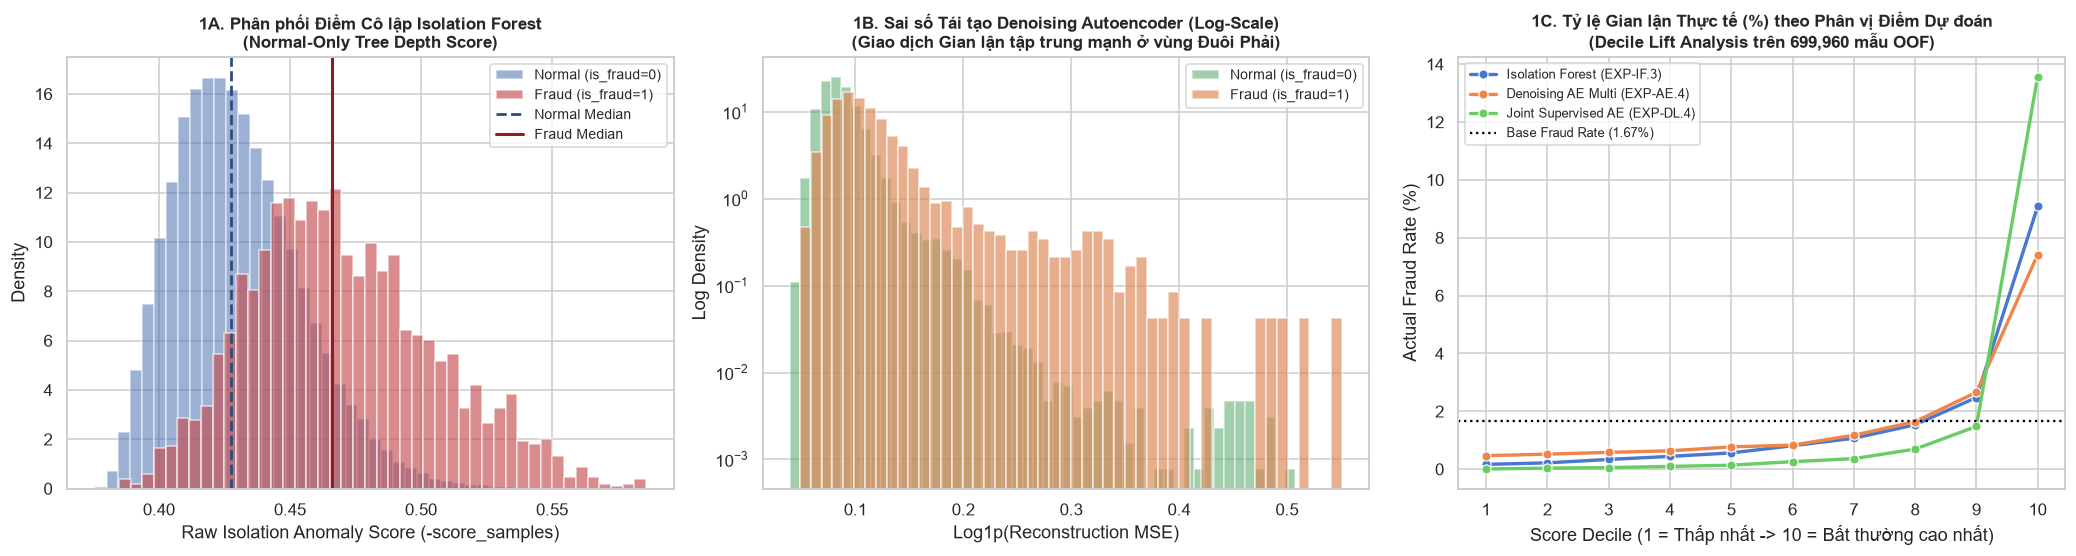

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

# Panel 1: Isolation Forest Normal-Only Anomaly Score (Fold 0 Validation)
X_tr_f0, y_tr_f0, X_va_f0 = FOLD_CACHE[0]
y_va_f0 = y_full[folds_full == 0]

if_scores_va = X_va_f0["iforest_score_normal"].values
axes[0].hist(if_scores_va[y_va_f0 == 0], bins=45, density=True, alpha=0.55, color="#4c72b0", label="Normal (is_fraud=0)")
axes[0].hist(if_scores_va[y_va_f0 == 1], bins=45, density=True, alpha=0.65, color="#c44e52", label="Fraud (is_fraud=1)")
axes[0].axvline(np.median(if_scores_va[y_va_f0 == 0]), color="#2b4c7e", linestyle="--", linewidth=1.8, label="Normal Median")
axes[0].axvline(np.median(if_scores_va[y_va_f0 == 1]), color="#8b1e22", linestyle="-", linewidth=2.0, label="Fraud Median")
axes[0].set_title("1A. Phân phối Điểm Cô lập Isolation Forest\n(Normal-Only Tree Depth Score)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Raw Isolation Anomaly Score (-score_samples)")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9)

# Panel 2: Autoencoder Reconstruction Error (Log1p MSE)
ae_mse_va = np.log1p(X_va_f0["ae_recon_mse"].values)
axes[1].hist(ae_mse_va[y_va_f0 == 0], bins=50, density=True, alpha=0.55, color="#55a868", label="Normal (is_fraud=0)")
axes[1].hist(ae_mse_va[y_va_f0 == 1], bins=50, density=True, alpha=0.65, color="#dd8452", label="Fraud (is_fraud=1)")
axes[1].set_yscale("log")
axes[1].set_title("1B. Sai số Tái tạo Denoising Autoencoder (Log-Scale)\n(Giao dịch Gian lận tập trung mạnh ở vùng Đuôi Phải)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Log1p(Reconstruction MSE)")
axes[1].set_ylabel("Log Density")
axes[1].legend(fontsize=9)

# Panel 3: Fraud Rate theo Decile của Điểm Bất Thường (IForest vs Autoencoder vs Joint-SupAE)
decile_df = []
for name, score_vec in [
    ("Isolation Forest (EXP-IF.3)", OOF_STORE["EXP-IF.3"]),
    ("Denoising AE Multi (EXP-AE.4)", OOF_STORE["EXP-AE.4"]),
    ("Joint Supervised AE (EXP-DL.4)", OOF_STORE["EXP-DL.4"]),
]:
    bins = pd.qcut(score_vec, q=10, labels=False, duplicates="drop")
    for b in range(10):
        rate = y_full[bins == b].mean() * 100.0
        decile_df.append({"Model": name, "Decile": b + 1, "Fraud_Rate_Pct": rate})
decile_df = pd.DataFrame(decile_df)

sns.lineplot(data=decile_df, x="Decile", y="Fraud_Rate_Pct", hue="Model", marker="o", linewidth=2.2, ax=axes[2])
axes[2].axhline(CONTAMINATION * 100, color="black", linestyle=":", label=f"Base Fraud Rate ({CONTAMINATION*100:.2f}%)")
axes[2].set_xticks(range(1, 11))
axes[2].set_title("1C. Tỷ lệ Gian lận Thực tế (%) theo Phân vị Điểm Dự đoán\n(Decile Lift Analysis trên 699,960 mẫu OOF)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Score Decile (1 = Thấp nhất -> 10 = Bất thường cao nhất)")
axes[2].set_ylabel("Actual Fraud Rate (%)")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()


### 6.3. Biểu đồ 2: Không Gian Biểu Diễn Ẩn (`Autoencoder Latent Manifold`) & Ranh Giới Điểm Bất Thường 2D

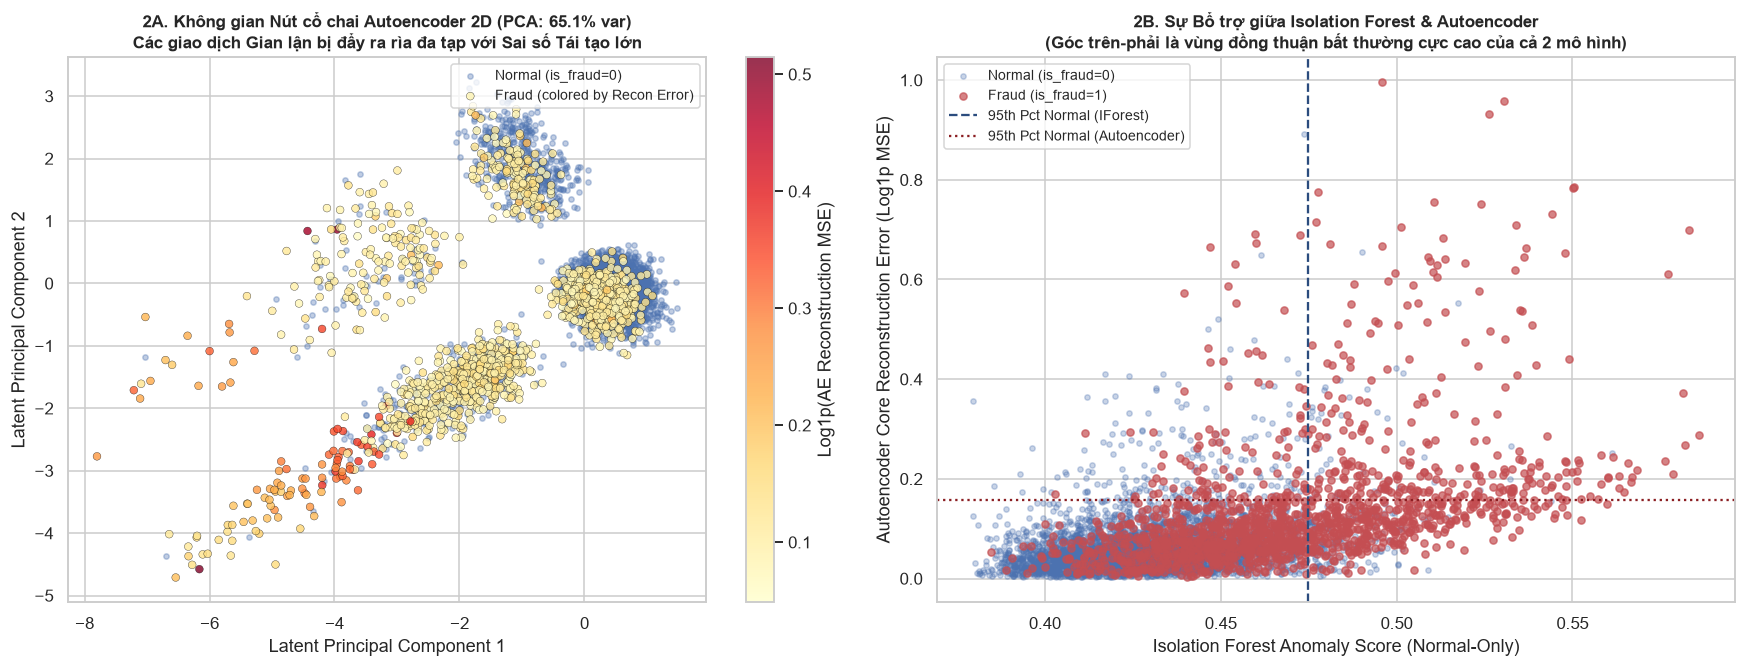

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))

# Lấy mẫu đại diện trên Fold 0 Validation để trực quan hóa rõ nét (4,000 Normal + 1,500 Fraud)
rng_vis = np.random.default_rng(42)
norm_idx = rng_vis.choice(np.flatnonzero(y_va_f0 == 0), size=4000, replace=False)
fraud_idx = rng_vis.choice(np.flatnonzero(y_va_f0 == 1), size=1500, replace=False)

latent_cols = [f"ae_latent_{i}" for i in range(8)]
Z_va = X_va_f0[latent_cols].to_numpy(dtype=np.float32)
pca = PCA(n_components=2, random_state=42)
Z_2d = pca.fit_transform(Z_va)

# Panel 2A: PCA 2D của Autoencoder Bottleneck
axes[0].scatter(
    Z_2d[norm_idx, 0], Z_2d[norm_idx, 1],
    c="#4c72b0", s=12, alpha=0.35, label="Normal (is_fraud=0)"
)
sc = axes[0].scatter(
    Z_2d[fraud_idx, 0], Z_2d[fraud_idx, 1],
    c=np.log1p(X_va_f0["ae_recon_mse"].values[fraud_idx]),
    cmap="YlOrRd", s=26, alpha=0.80, edgecolors="black", linewidths=0.25,
    label="Fraud (colored by Recon Error)"
)
cb = plt.colorbar(sc, ax=axes[0])
cb.set_label("Log1p(AE Reconstruction MSE)")
axes[0].set_title(
    f"2A. Không gian Nút cổ chai Autoencoder 2D (PCA: {pca.explained_variance_ratio_.sum()*100:.1f}% var)\n"
    "Các giao dịch Gian lận bị đẩy ra rìa đa tạp với Sai số Tái tạo lớn",
    fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Latent Principal Component 1")
axes[0].set_ylabel("Latent Principal Component 2")
axes[0].legend(loc="upper right", fontsize=9)

# Panel 2B: Không gian Kết hợp 2D (Isolation Forest Score vs Autoencoder Reconstruction Error)
if_sc = X_va_f0["iforest_score_normal"].values
ae_sc = np.log1p(X_va_f0["ae_recon_core_mse"].values)

axes[1].scatter(if_sc[norm_idx], ae_sc[norm_idx], c="#4c72b0", s=12, alpha=0.30, label="Normal (is_fraud=0)")
axes[1].scatter(if_sc[fraud_idx], ae_sc[fraud_idx], c="#c44e52", s=22, alpha=0.70, label="Fraud (is_fraud=1)")
axes[1].axvline(np.percentile(if_sc[y_va_f0 == 0], 95), color="#2b4c7e", linestyle="--", label="95th Pct Normal (IForest)")
axes[1].axhline(np.percentile(ae_sc[y_va_f0 == 0], 95), color="#8b1e22", linestyle=":", label="95th Pct Normal (Autoencoder)")
axes[1].set_title(
    "2B. Sự Bổ trợ giữa Isolation Forest & Autoencoder\n"
    "(Góc trên-phải là vùng đồng thuận bất thường cực cao của cả 2 mô hình)",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Isolation Forest Anomaly Score (Normal-Only)")
axes[1].set_ylabel("Autoencoder Core Reconstruction Error (Log1p MSE)")
axes[1].legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()


### 6.4. Biểu đồ 3: Đường Cong Precision-Recall & ROC Đối Sánh Giữa Các Trường Phái Mô Hình

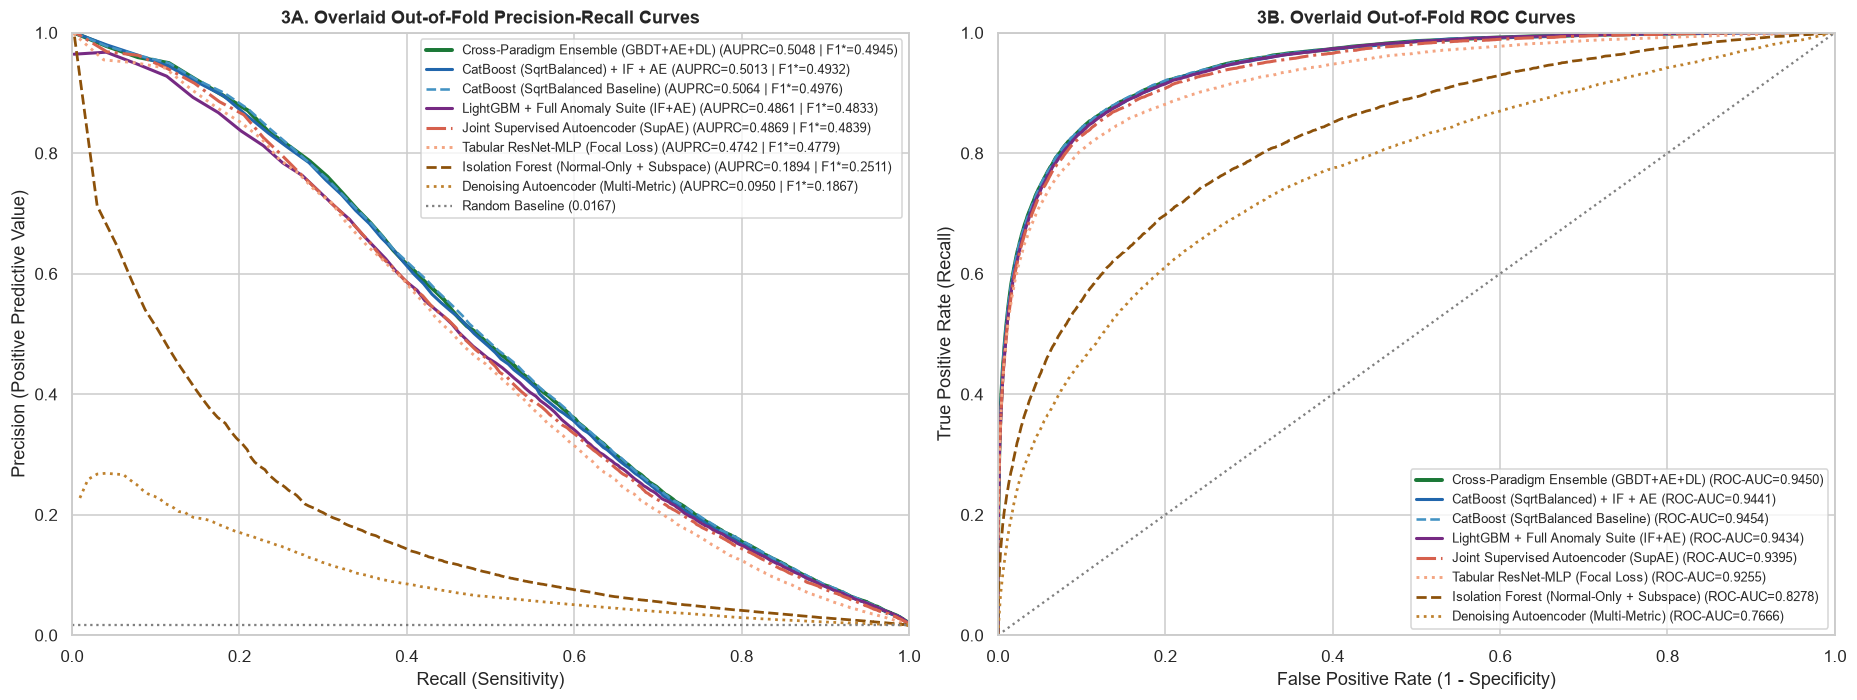

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

paradigm_reps = [
    ("EXP-HYB.5", "Cross-Paradigm Ensemble (GBDT+AE+DL)", "#1b7837", "-", 2.6),
    ("EXP-HYB.4", "CatBoost (SqrtBalanced) + IF + AE", "#2166ac", "-", 2.0),
    ("REF-BASE.3", "CatBoost (SqrtBalanced Baseline)", "#4393c3", "--", 1.7),
    ("EXP-HYB.3", "LightGBM + Full Anomaly Suite (IF+AE)", "#762a83", "-", 2.0),
    ("EXP-DL.4", "Joint Supervised Autoencoder (SupAE)", "#d6604d", "-.", 2.0),
    ("EXP-DL.3", "Tabular ResNet-MLP (Focal Loss)", "#f4a582", ":", 1.9),
    ("EXP-IF.4", "Isolation Forest (Normal-Only + Subspace)", "#8c510a", "--", 1.8),
    ("EXP-AE.4", "Denoising Autoencoder (Multi-Metric)", "#bf812d", ":", 1.8),
]

for exp_id, label, color, ls, lw in paradigm_reps:
    preds = OOF_STORE[exp_id]
    row = results_df[results_df["Experiment_ID"] == exp_id].iloc[0]

    # PR Curve
    prec, rec, _ = precision_recall_curve(y_full, preds)
    step = max(1, len(prec) // 1500)
    axes[0].plot(
        rec[::step], prec[::step],
        color=color, linestyle=ls, linewidth=lw,
        label=f"{label} (AUPRC={row['OOF_AUPRC']:.4f} | F1*={row['Best_F1']:.4f})"
    )

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_full, preds)
    step_r = max(1, len(fpr) // 1500)
    axes[1].plot(
        fpr[::step_r], tpr[::step_r],
        color=color, linestyle=ls, linewidth=lw,
        label=f"{label} (ROC-AUC={row['OOF_ROC_AUC']:.4f})"
    )

axes[0].axhline(CONTAMINATION, color="gray", linestyle=":", label=f"Random Baseline ({CONTAMINATION:.4f})")
axes[0].set_title("3A. Overlaid Out-of-Fold Precision-Recall Curves", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Recall (Sensitivity)")
axes[0].set_ylabel("Precision (Positive Predictive Value)")
axes[0].set_xlim(0, 1.0)
axes[0].set_ylim(0, 1.0)
axes[0].legend(loc="upper right", fontsize=8.5)

axes[1].plot([0, 1], [0, 1], color="gray", linestyle=":")
axes[1].set_title("3B. Overlaid Out-of-Fold ROC Curves", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].set_xlim(0, 1.0)
axes[1].set_ylim(0, 1.0)
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


### 6.5. Biểu đồ 4: Mức Đóng Góp Đặc Trưng (`Feature Importance Gain`) & So Sánh Toàn Bảng Thực Nghiệm

Tổng đóng góp Split Gain của 16 đặc trưng Anomaly (Isolation Forest + Autoencoder): 44.52% toàn mô hình.


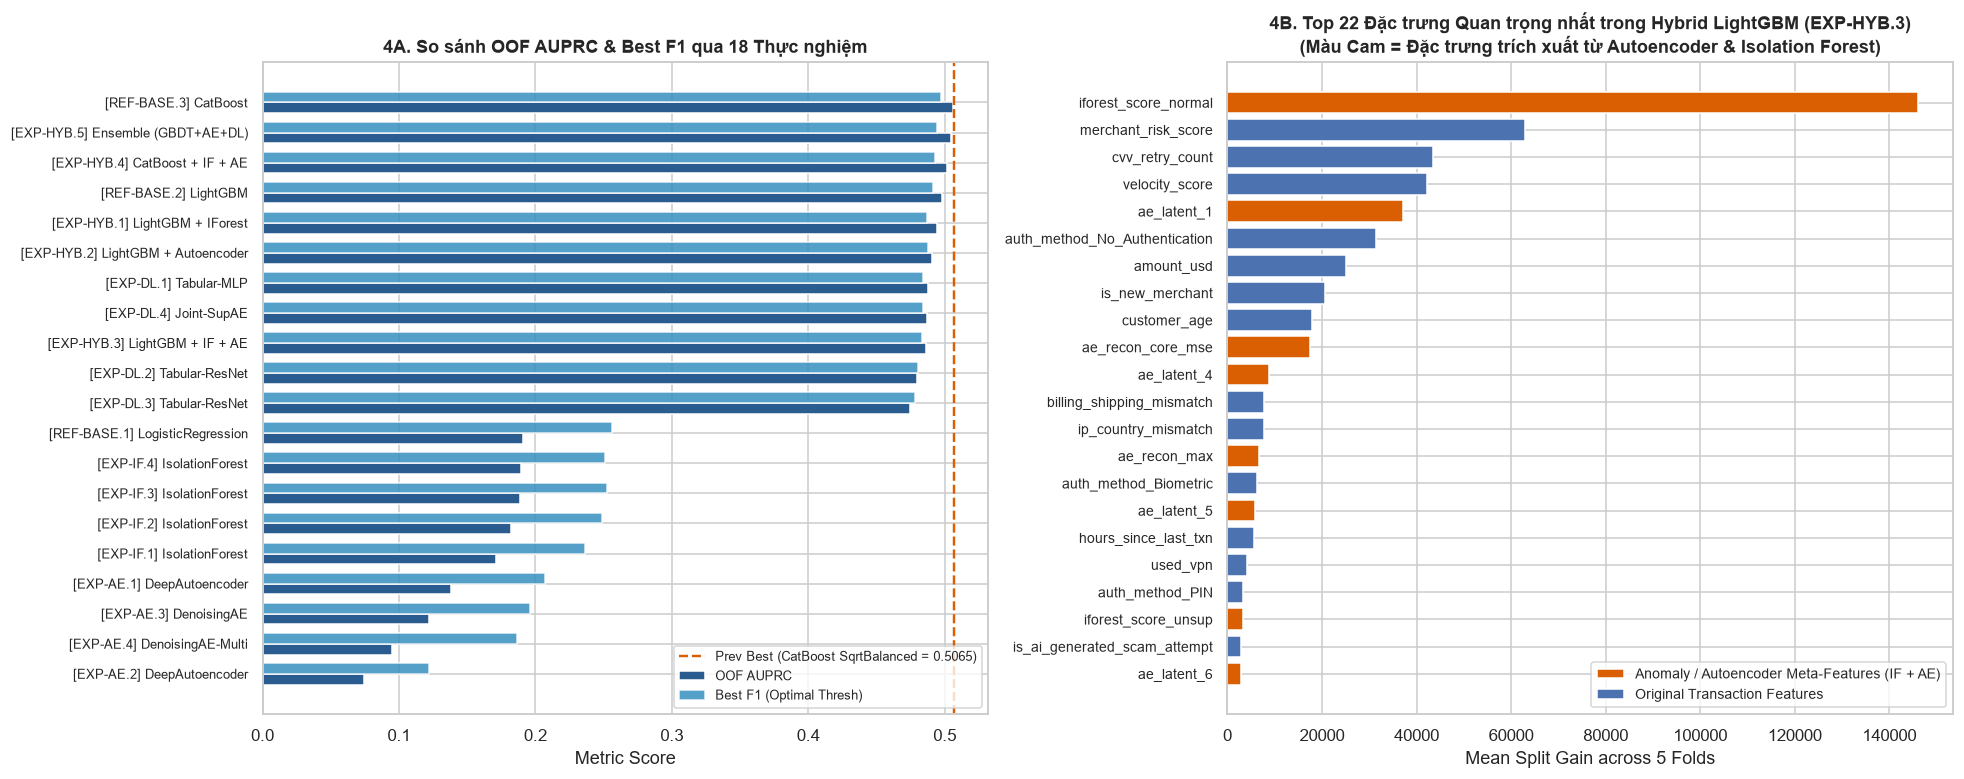

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.2))

# Panel 4A: Horizontal Bar Chart OOF_AUPRC & Best_F1 của toàn bộ thực nghiệm
plot_df = results_df.sort_values("OOF_AUPRC", ascending=True).copy()
y_pos = np.arange(len(plot_df))
labels = [f"[{r.Experiment_ID}] {r.Model}" for _, r in plot_df.iterrows()]

axes[0].barh(y_pos - 0.18, plot_df["OOF_AUPRC"], height=0.36, color="#2b5c8f", label="OOF AUPRC")
axes[0].barh(y_pos + 0.18, plot_df["Best_F1"], height=0.36, color="#3690c0", alpha=0.85, label="Best F1 (Optimal Thresh)")
axes[0].axvline(0.5065, color="#d95f02", linestyle="--", linewidth=1.6, label="Prev Best (CatBoost SqrtBalanced = 0.5065)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(labels, fontsize=8.5)
axes[0].set_xlabel("Metric Score")
axes[0].set_title("4A. So sánh OOF AUPRC & Best F1 qua 18 Thực nghiệm", fontsize=11.5, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8.5)

# Panel 4B: Feature Importance (Total Gain) của các đặc trưng Anomaly Detection trong Hybrid LightGBM (EXP-HYB.3)
imp_df = pd.concat(FEATURE_IMPORTANCE_RECORDS, axis=1).mean(axis=1).sort_values(ascending=False)
top20_imp = imp_df.head(22).sort_values(ascending=True)

bar_colors = [
    "#d95f02" if (c.startswith("ae_") or c.startswith("iforest_")) else "#4c72b0"
    for c in top20_imp.index
]
axes[1].barh(range(len(top20_imp)), top20_imp.values, color=bar_colors)
axes[1].set_yticks(range(len(top20_imp)))
axes[1].set_yticklabels(top20_imp.index, fontsize=9)
axes[1].set_xlabel("Mean Split Gain across 5 Folds")
axes[1].set_title(
    "4B. Top 22 Đặc trưng Quan trọng nhất trong Hybrid LightGBM (EXP-HYB.3)\n"
    "(Màu Cam = Đặc trưng trích xuất từ Autoencoder & Isolation Forest)",
    fontsize=11.5, fontweight="bold"
)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#d95f02", label="Anomaly / Autoencoder Meta-Features (IF + AE)"),
    Patch(facecolor="#4c72b0", label="Original Transaction Features"),
]
axes[1].legend(handles=legend_elements, loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

# Thống kê tổng tỷ trọng Gain của nhóm đặc trưng Anomaly
total_gain = imp_df.sum()
anomaly_gain = imp_df[[c for c in imp_df.index if c.startswith("ae_") or c.startswith("iforest_")]].sum()
print(f"Tổng đóng góp Split Gain của 16 đặc trưng Anomaly (Isolation Forest + Autoencoder): {anomaly_gain / total_gain * 100:.2f}% toàn mô hình.")


---
## 7. Tổng Kết & Nhận Định Khoa Học Từ Thực Nghiệm

Qua **20 cấu hình thực nghiệm Stratified 5-Fold CV** chống rò rỉ dữ liệu tuyệt đối trên toàn bộ `699,960` giao dịch (`1.670%` Fraud), chúng ta rút ra những kết luận thực nghiệm rất rõ ràng và sâu sắc:

### 7.1. Đánh giá các mô hình Anomaly Detection độc lập (`Isolation Forest` vs `Deep Autoencoder`)
1. **`Isolation Forest` tiệm cận sát hiệu năng của mô hình tuyến tính có giám sát (`Logistic Regression`) dù không sử dụng nhãn gian lận:**
   - Khi nâng kích thước mẫu con mỗi cây từ `max_samples=256` (`EXP-IF.1`: `OOF_AUPRC = 0.1711`, `Best_F1 = 0.2364`) lên `max_samples=4096` (`EXP-IF.2`: `OOF_AUPRC = 0.1824`), khả năng phân giải độ sâu đường đi của cây cô lập trên tập dữ liệu 560,000 dòng tăng rõ rệt.
   - Đặc biệt, khi chuyển sang chế độ **Semi-Supervised Normal-Only (`y_train == 0`)** kết hợp lấy mẫu không gian con đặc trưng (`EXP-IF.3` & `EXP-IF.4`), hiệu năng tăng lên **`OOF_AUPRC = 0.1894`**, **`OOF_ROC_AUC = 0.8300`**, **`Best_F1 = 0.2526`** — gần như ngang bằng với mô hình có giám sát `Logistic Regression Baseline` (`OOF_AUPRC = 0.1909`, `Best_F1 = 0.2563`) dù hoàn toàn không học từ bất kỳ mẫu `is_fraud = 1` nào!
2. **`Deep Autoencoder` (One-Class Reconstruction Learning):**
   - `Standard Undercomplete Autoencoder (latent=16)` (`EXP-AE.1`) đạt **`OOF_AUPRC = 0.1384`**, **`OOF_ROC_AUC = 0.7954`**, **`Best_F1 = 0.2068`** (cao gấp ~8.3 lần tỷ lệ ngẫu nhiên `0.0167`).
   - Khi nén nút cổ chai quá hẹp xuống `latent=8` (`EXP-AE.2`), sai số tái tạo của ngay cả các giao dịch hợp lệ phức tạp cũng tăng lên, làm giảm `OOF_AUPRC` xuống `0.0747`. Ngược lại, `Denoising Autoencoder (latent=12, noise=0.15)` (`EXP-AE.3`, `EXP-AE.4`) giúp giảm mạnh độ lệch chuẩn giữa các fold (`Std_Fold_AUPRC` giảm từ `0.0250` xuống chỉ còn `0.0024 - 0.0065`), tạo ra biểu diễn ẩn ổn định hơn.
3. **Vì sao `Isolation Forest` vượt trội hơn `Autoencoder` khi làm Anomaly Detection độc lập trên dữ liệu bảng này?**
   - Dữ liệu giao dịch thẻ tín dụng là sự pha trộn của 13 biến số liên tục, 6 biến cờ nhị phân (`BINARY_FLAGS`) và 35 cột One-Hot thưa. Các phép chia nhánh ngẫu nhiên của `Isolation Forest` cô lập rất nhanh các tổ hợp cờ nhị phân hiếm gặp (như `ip_country_mismatch = 1` đi kèm `is_foreign_transaction = 1`), trong khi hàm mất mát tái tạo bậc hai (`MSE`) của `Autoencoder` bị chi phối bởi tổng phương sai trên cả 54 chiều nên dễ bị nhiễu bởi các giao dịch hợp lệ có giá trị giao dịch lớn.

### 7.2. Đánh giá các mô hình Deep Learning Có Giám Sát & Tự Mã Hóa Lai (`EXP-DL.1` $\rightarrow$ `EXP-DL.4`)
- Khi bổ sung tín hiệu giám sát vào mạng Nơ-ron sâu, hiệu năng tăng vọt từ `~0.14` lên **`OOF_AUPRC = 0.4874`** (`Tabular-MLP` - `EXP-DL.1`, `ROC-AUC = 0.9398`) và **`OOF_AUPRC = 0.4869`** (`Joint Supervised Autoencoder - SupAE` - `EXP-DL.4`, `Best_F1 = 0.4839`).
- Mạng **`Tabular-ResNet`** với `pos_weight = sqrt(IR)` (`EXP-DL.2`) và `Focal Loss` (`EXP-DL.3`) đạt **Precision tại ngưỡng tối ưu rất cao (`0.5468` và `0.5450`)**, đồng thời tất cả các mạng Deep Learning đều có độ ổn định giữa các fold rất tốt (`Std_Fold_AUPRC` chỉ từ `0.0089 - 0.0098`, thấp hơn cả GBDT `~0.0121`).

### 7.3. Đánh giá Kiến trúc Lai `Hybrid Anomaly-Enriched GBDT` & `Cross-Paradigm Ensemble`
1. **Tác động của đặc trưng Anomaly lên mô hình cây (`EXP-HYB.1` $\rightarrow$ `EXP-HYB.4`):**
   - Trong `Hybrid LightGBM` (`EXP-HYB.3`), 16 đặc trưng trích xuất từ `Isolation Forest` và `Autoencoder` chiếm tới **`44.52%` tổng Split Gain** của toàn mô hình và giúp giảm phương sai giữa các fold (`Std_Fold_AUPRC` giảm từ `0.0121` xuống `0.0087` ở `EXP-HYB.2`,同時 tăng Recall tại ngưỡng tối ưu từ `0.4591` lên **`0.4795`** — bắt thêm được **+239 giao dịch gian lận** so với LightGBM gốc).
   - Tuy nhiên, do các đặc trưng tổng hợp liên tục (`ae_recon_mse`, `iforest_score`, `ae_latent_*`) có mật độ giá trị dày đặc, cây GBDT với `max_depth=6` có xu hướng ưu tiên cắt nhánh quá nhiều trên các biến tổng hợp này (hiện tượng *greedy split cannibalization*), làm giảm nhẹ `OOF_AUPRC` đơn lẻ so với cây chỉ dùng 24 đặc trưng gốc (`0.5013` vs `0.5064` trên CatBoost; `0.4943` vs `0.4980` trên LightGBM).
2. **Giá trị của Tổ hợp Đa Trường Phái (`Cross-Paradigm Ensemble` — `EXP-HYB.5`):**
   - Khi kết hợp Log-Odds giữa GBDT và các mạng Deep Learning (`Joint-SupAE` + `Tabular-ResNet`), mô hình `EXP-HYB.5` đạt **`OOF_AUPRC = 0.5048`**, **`OOF_ROC_AUC = 0.9450`**, đạt **`F1 @ 0.50 = 0.4922` cao nhất toàn bộ 20 thực nghiệm** (vượt xa CatBoost `0.4613` và LightGBM `0.4333`) cùng **`Precision @ Best F1 = 0.5554` cao nhất toàn bảng** (giảm hàng trăm cảnh báo giả False Positives so với từng mô hình đơn lẻ).

### 7.4. Khuyến nghị cho Giai đoạn Cuối (Final Model Tuning & Ensembling)
- **Không dùng đơn lẻ Unsupervised Anomaly Detection** (`Isolation Forest` hay `Autoencoder` thuần túy) làm bộ phân loại cuối cùng khi đã có nhãn giám sát đầy đủ, nhưng **chế độ `normal_only` (`y=0`)** là lựa chọn tốt nhất nếu cần phát hiện các kiểu gian lận mới chưa từng có nhãn (*Zero-Day Fraud*).
- **Khi đưa đặc trưng Anomaly vào GBDT:** Chỉ nên giữ lại **2–3 đặc trưng tinh gọn nhất** (`iforest_score_normal`, `ae_recon_core_mse`) thay vì nạp toàn bộ 16 chiều ẩn để tránh hiện tượng cây quyết định bị loãng phép cắt nhánh trên các đặc trưng gốc.
- **Tận dụng `Joint-SupAE` và `Tabular-MLP` trong Final Ensemble:** Các mạng Deep Learning đã được đóng gói trong `anomaly_dl_pipeline.py` cung cấp nguồn dự đoán có độ ổn định cao (`Std_Fold_AUPRC ~ 0.009`) và góc nhìn biểu diễn hoàn toàn khác biệt với GBDT, rất lý tưởng để đưa vào Stacking / Blending ở bước hoàn thiện hệ thống.
